# ML Numericals Solved by Hand: Part 2, Trees, SVMs, Unsupervised Learning, Anomaly Detection, Recommenders and RL

> **Who is this for:** students preparing for an ML exam or interview, and anyone who wants to see the actual arithmetic behind tree splits, boosting, SVMs, clustering, PCA, EM, anomaly detection, recommenders and basic reinforcement learning. Every problem uses tiny numbers so you can solve it with a pen, paper and a basic calculator.
>
> **What you will learn:**
> - Decision trees: entropy, Gini impurity and information gain; regression trees by variance reduction
> - Ensembles: bootstrap samples and out-of-bag rows, majority voting, one round of AdaBoost, one step of gradient boosting
> - SVMs: margin width, functional vs geometric margin, hinge loss; RBF and polynomial kernel values
> - Unsupervised learning: k-means, hierarchical clustering (single vs complete linkage), DBSCAN, PCA, EM for a Gaussian mixture, Apriori support, confidence and lift
> - Anomaly detection with a Gaussian density, and choosing the threshold $\varepsilon$ by F1
> - Recommender systems: content-based prediction, collaborative-filtering cost and gradient, the like/dislike (logistic) version, mean normalization
> - Reinforcement learning: discounted return, the Bellman equation, value iteration, policy iteration, a Q-learning update, $\varepsilon$-greedy and soft target updates
>
> **Prerequisites:** [Part 1: metrics, regression and classification numericals](00c_ml_numericals_solved_by_hand.ipynb) (F1, gradient descent, sigmoid, log loss) and [Your first ML model](00_start_here_your_first_ml_model.ipynb). Basic algebra: squares, square roots, $e^x$, $\ln$ and $\log_2$.
>
> **Time needed:** about 3-4 hours with pen and paper (19 worked problems plus 19 practice problems). The code runs in a few seconds.
>
> **Runs on:** CPU, no API key, no internet. Uses numpy, pandas, scipy, scikit-learn and matplotlib; every dataset is typed in by hand.

## Explained simply

A **numerical** is a small worked problem with real numbers, like "here are 8 customers, which question should the tree ask first?" or "here are 6 points, where do the k-means centres end up after two rounds?". Exams love them because you cannot answer by memorising words: you have to know what the algorithm actually computes.

Doing one by hand is like cooking a dish yourself once before buying the ready meal. Afterwards `DecisionTreeClassifier().fit(...)` or `KMeans().fit(...)` is no longer a black box: you know which numbers it compares, why it picks one option over another, and what a strange result might mean.

**How to use this notebook**

1. Read the **Problem**, cover the solution, and try it on paper.
2. Compare with the **Solution by hand**: every step and every intermediate number is written out.
3. Run the **code cell**: it recomputes the answer with numpy and scikit-learn and stops with an error (`assert`) if the code and the hand answer disagree. So every number in the text has been checked.
4. Do the **Try it yourself** problem; the answer is hidden behind a click.

**Conventions used throughout**

- Numbers are rounded to **4 decimals** unless a step needs more (then we say so). The calculator keeps full precision, like the code, so do not round in the middle of a long chain.
- $\ln$ is the natural log; entropy uses $\log_2$ (answers in bits).
- Where books disagree on a convention (dividing by $m$ or $m-1$, whether DBSCAN counts a point as its own neighbour, which reward counts in a return), we state the one we use and the one scikit-learn uses.

## Contents

| # | Section | Go deeper in this repo |
|---|---|---|
| 0 | Setup | - |
| | **Part A: Trees and ensembles** | |
| 1 | Decision tree split: entropy, Gini and information gain | [decision trees](01_supervised/03_decision_trees.ipynb) |
| 2 | Regression tree split: variance reduction | [decision trees](01_supervised/03_decision_trees.ipynb) |
| 3 | Bagging and random forests: bootstrap, out-of-bag rows, voting | [ensemble methods](01_supervised/04_ensemble_methods.ipynb) |
| 4 | AdaBoost: one boosting round | [ensemble methods](01_supervised/04_ensemble_methods.ipynb) |
| 5 | Gradient boosting: one residual-fitting step | [ensemble methods](01_supervised/04_ensemble_methods.ipynb) |
| | **Part B: SVMs and kernels** | |
| 6 | SVM: margin, functional vs geometric margin, hinge loss | [SVM](01_supervised/05_svm.ipynb) |
| 7 | Kernels: RBF and polynomial | [kernel methods](16_learning_theory/02_kernel_methods.ipynb) |
| | **Part C: Unsupervised learning** | |
| 8 | K-means: two full iterations | [clustering](02_unsupervised/01_clustering.ipynb) |
| 9 | Hierarchical clustering: single vs complete linkage | [clustering](02_unsupervised/01_clustering.ipynb) |
| 10 | DBSCAN: core, border and noise points | [clustering in depth](02_unsupervised/05_clustering_and_manifold_learning_in_depth.ipynb) |
| 11 | PCA by hand on a 2-D dataset | [dimensionality reduction](02_unsupervised/02_dimensionality_reduction.ipynb) |
| 12 | EM for a mixture of two Gaussians | [EM and variational inference](17_probabilistic_graphical_models/02_em_variational_inference_and_sampling.ipynb) |
| 13 | Apriori: support, confidence and lift | [association rules](02_unsupervised/03_association_rules.ipynb) |
| | **Part D: Anomaly detection** | |
| 14 | Gaussian anomaly detection and choosing $\varepsilon$ by F1 | [anomaly detection](08_anomaly_detection/01_anomaly_detection.ipynb) |
| | **Part E: Recommender systems** | |
| 15 | Content-based prediction and the collaborative-filtering cost | [recommendation systems](09_recommendation_systems/01_recommendation_systems.ipynb) |
| 16 | Mean normalization for new users | [recommendation systems](09_recommendation_systems/01_recommendation_systems.ipynb) |
| | **Part F: Reinforcement learning** | |
| 17 | Discounted return on a 1-D line of states | [RL fundamentals](../11_Reinforcement_Learning/01_rl_fundamentals.ipynb) |
| 18 | Bellman equation, value iteration and policy iteration | [dynamic programming](../11_Reinforcement_Learning/02_dynamic_programming.ipynb) |
| 19 | Q-learning update, $\varepsilon$-greedy and soft target updates | [tabular RL from scratch](../11_Reinforcement_Learning/09_tabular_rl_from_scratch.ipynb), [DQN](../11_Reinforcement_Learning/04_deep_q_networks.ipynb) |
| - | Recap cheat sheet, related notebooks, resources | - |

## 0. Setup

We import numpy (arrays), pandas (small tables), scipy (normal densities, hierarchical clustering), scikit-learn (the library versions of each algorithm) and matplotlib (plots). `check(name, code_value, hand_value)` prints the code result next to the hand answer and **stops with an error if they disagree** (beyond the rounding of the last decimal shown).

In [1]:
import warnings
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
from scipy.stats import norm                                  # normal (Gaussian) density
from scipy.special import expit                               # sigmoid 1 / (1 + e^-z)
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
import sklearn
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingRegressor
from sklearn.metrics import hinge_loss, f1_score
from sklearn.metrics.pairwise import rbf_kernel, polynomial_kernel
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from sklearn.exceptions import ConvergenceWarning

SEED = 42                                                     # fixed seed -> the same numbers on every run
np.random.seed(SEED)
rng = np.random.default_rng(SEED)
pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.figsize": (6, 3.4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#52514e"   # plot colours used in this notebook

def check(name, code_value, hand_value, dp=4):
    """Print the code result next to the hand answer and stop with an error if they disagree.
    dp = decimals the hand answer was rounded to; the two must agree within half of that last digit."""
    code_value = float(code_value)
    ok = np.isclose(code_value, hand_value, rtol=0, atol=0.5 * 10**-dp + 1e-12)
    print(f"{name:<40} code = {code_value:>11.{dp}f}   by hand = {hand_value:>11.{dp}f}   {'OK' if ok else 'MISMATCH'}")
    assert ok, f"{name}: code gives {code_value}, the hand answer is {hand_value}"

print("numpy", np.__version__, "| scipy", scipy.__version__, "| scikit-learn", sklearn.__version__)

numpy 2.1.3 | scipy 1.18.1 | scikit-learn 1.5.2


---
**Part A: Trees and ensembles**

## 1. Decision tree split: entropy, Gini and information gain

**What it is:** a decision tree asks yes/no questions. At each node it picks the question that leaves the groups below it as **pure** as possible (ideally one class each). **Analogy:** sorting a bag of mixed red and blue marbles into two boxes with one question; a good question puts mostly red in one box and mostly blue in the other.

### Problem

A shop recorded 8 customers. Should the root of the tree split on **Student** or on **Income**? Use information gain (entropy), then check with Gini impurity.

| # | Student | Income | Buys |
|---|---|---|---|
| 1 | yes | high | yes |
| 2 | no | high | no |
| 3 | yes | low | yes |
| 4 | no | high | yes |
| 5 | yes | high | no |
| 6 | no | low | no |
| 7 | yes | low | yes |
| 8 | no | high | no |

### Solution by hand

With $p_k$ = fraction of class $k$ in a node:
$$H = -\sum_k p_k \log_2 p_k \qquad G = 1 - \sum_k p_k^2 \qquad IG = H(\text{parent}) - \sum_{\text{children}} \frac{n_\text{child}}{n}\,H(\text{child})$$

1. **Parent node:** 4 yes, 4 no, so $p = (0.5, 0.5)$. $H = -2 \times 0.5\log_2 0.5 = 1.0$ and $G = 1 - (0.25 + 0.25) = 0.5$.
2. **Split on Student.**
   - Student = yes (rows 1, 3, 5, 7): 3 yes, 1 no. $H = -(0.75\log_2 0.75 + 0.25\log_2 0.25) = 0.3113 + 0.5 = 0.8113$.
   - Student = no (rows 2, 4, 6, 8): 1 yes, 3 no. Same proportions, so the same $H = 0.8113$.
   - Weighted: $\frac48(0.8113) + \frac48(0.8113) = 0.8113$, so $IG = 1 - 0.8113 = 0.1887$.
3. **Split on Income.**
   - Income = high (rows 1, 2, 4, 5, 8): 2 yes, 3 no. $H = -(0.4\log_2 0.4 + 0.6\log_2 0.6) = 0.5288 + 0.4422 = 0.9710$.
   - Income = low (rows 3, 6, 7): 2 yes, 1 no. $H = -(\tfrac23\log_2\tfrac23 + \tfrac13\log_2\tfrac13) = 0.3900 + 0.5283 = 0.9183$.
   - Weighted: $\frac58(0.9710) + \frac38(0.9183) = 0.9512$, so $IG = 1 - 0.9512 = 0.0488$.
4. **The same comparison with Gini.**
   - Student: each child has $G = 1 - (0.75^2 + 0.25^2) = 1 - 0.625 = 0.375$; weighted $0.375$; gain $0.5 - 0.375 = 0.125$.
   - Income: high $G = 1 - (0.4^2 + 0.6^2) = 0.48$; low $G = 1 - (\tfrac49 + \tfrac19) = 0.4444$; weighted $\frac58(0.48) + \frac38(0.4444) = 0.3 + 0.1667 = 0.4667$; gain $0.5 - 0.4667 = 0.0333$.
5. **Answer:** split on **Student** (IG $0.1887$ vs $0.0488$; Gini gain $0.125$ vs $0.0333$). Both criteria agree, as they usually do.

In [2]:
# Encode the table as 0/1 columns: Student (1 = yes), Income (1 = high); target Buys (1 = yes)
student = np.array([1, 0, 1, 0, 1, 0, 1, 0])
income  = np.array([1, 1, 0, 1, 1, 0, 0, 1])
buys    = np.array([1, 0, 1, 1, 0, 0, 1, 0])

def entropy(y):
    p = np.bincount(y, minlength=2) / len(y)
    p = p[p > 0]                                   # 0 * log(0) counts as 0
    return -(p * np.log2(p)).sum()

def gini(y):
    p = np.bincount(y, minlength=2) / len(y)
    return 1 - (p ** 2).sum()

def gain(feature, y, impurity):
    children = [y[feature == v] for v in (0, 1)]
    weighted = sum(len(c) / len(y) * impurity(c) for c in children)
    return impurity(y) - weighted

check("parent entropy", entropy(buys), 1.0)
check("IG(Student)", gain(student, buys, entropy), 0.1887)
check("IG(Income)", gain(income, buys, entropy), 0.0488)
check("Gini gain(Student)", gain(student, buys, gini), 0.125)
check("Gini gain(Income)", gain(income, buys, gini), 0.0333)

tree = DecisionTreeClassifier(criterion="entropy", max_depth=1, random_state=SEED)
tree.fit(np.c_[student, income], buys)
root = ["Student", "Income"][tree.tree_.feature[0]]
print("\nscikit-learn's root split:", root)
check("sklearn: entropy of a child node", tree.tree_.impurity[1], 0.8113)
assert root == "Student"

parent entropy                           code =      1.0000   by hand =      1.0000   OK
IG(Student)                              code =      0.1887   by hand =      0.1887   OK
IG(Income)                               code =      0.0488   by hand =      0.0488   OK
Gini gain(Student)                       code =      0.1250   by hand =      0.1250   OK
Gini gain(Income)                        code =      0.0333   by hand =      0.0333   OK

scikit-learn's root split: Student
sklearn: entropy of a child node         code =      0.8113   by hand =      0.8113   OK


### Try it yourself

A node holds 3 "yes" and 3 "no". A split sends 2 rows (both yes) to the left and 4 rows (1 yes, 3 no) to the right. Compute the information gain and the Gini gain.

<details><summary>Answer</summary>

Parent: $H = 1$, $G = 0.5$. The left child is pure: $H = 0$, $G = 0$. The right child: $H = 0.8113$, $G = 0.375$.

Weighted entropy $= \frac46(0.8113) = 0.5409$, so $IG = 1 - 0.5409 = 0.4591$. Weighted Gini $= \frac46(0.375) = 0.25$, so the Gini gain is $0.5 - 0.25 = 0.25$.
</details>

**Exam tip:** two children with the same class proportions have the same entropy, so reuse the number. Entropy uses $\log_2$; with $\ln$ you get different numbers (in "nats").

## 2. Regression tree split: variance reduction

**What it is:** when the target is a number, a tree splits where the two groups have the **smallest spread around their own mean**, and each leaf predicts its group's mean. **Analogy:** splitting a class into two reading groups so that the students within each group are at similar levels.

### Problem

Six flats: $x$ = floor area (in 10 m²), $y$ = monthly rent (in \$100s). Which threshold should a depth-1 regression tree use? Compare the splits $x < 2.5$, $x < 3.5$ and $x < 4.5$ by the total sum of squared errors (SSE).

| $x$ | 1 | 2 | 3 | 4 | 5 | 6 |
|---|---|---|---|---|---|---|
| $y$ | 5 | 7 | 6 | 14 | 18 | 16 |

### Solution by hand

$\text{SSE(node)} = \sum (y - \bar y_\text{node})^2$. Variance reduction $= \text{SSE(parent)} - [\text{SSE(left)} + \text{SSE(right)}]$ (divide everything by $n$ to talk about variances instead).

1. **Parent:** $\bar y = 66/6 = 11$. SSE $= 36 + 16 + 25 + 9 + 49 + 25 = 160$ (variance $160/6 = 26.6667$).
2. **$x < 2.5$:** left $\{5, 7\}$, mean 6, SSE $= 1 + 1 = 2$. Right $\{6, 14, 18, 16\}$, mean $54/4 = 13.5$, SSE $= 56.25 + 0.25 + 20.25 + 6.25 = 83$. Total $85$, reduction $75$.
3. **$x < 3.5$:** left $\{5, 7, 6\}$, mean 6, SSE $= 1 + 1 + 0 = 2$. Right $\{14, 18, 16\}$, mean 16, SSE $= 4 + 4 + 0 = 8$. Total $10$, reduction $150$.
4. **$x < 4.5$:** left $\{5, 7, 6, 14\}$, mean 8, SSE $= 9 + 1 + 4 + 36 = 50$. Right $\{18, 16\}$, mean 17, SSE $= 1 + 1 = 2$. Total $52$, reduction $108$.
5. **Answer:** split at $x < 3.5$. The leaves predict **6** (left) and **16** (right). In variance terms: $26.6667 - \frac{10}{6} = 26.6667 - 1.6667 = 25.0$.

In [3]:
x = np.array([1, 2, 3, 4, 5, 6])
y = np.array([5, 7, 6, 14, 18, 16])

def sse(values):
    return ((values - values.mean()) ** 2).sum()   # squared errors around the node's own mean

rows = []
for t in [1.5, 2.5, 3.5, 4.5, 5.5]:
    left, right = y[x < t], y[x > t]
    rows.append({"threshold": t, "SSE left": sse(left), "SSE right": sse(right),
                 "total SSE": sse(left) + sse(right), "reduction": sse(y) - sse(left) - sse(right)})
table = pd.DataFrame(rows)
print(table.to_string(index=False), "\n")

check("parent SSE", sse(y), 160)
check("total SSE, x < 2.5", table.loc[1, "total SSE"], 85)
check("total SSE, x < 3.5", table.loc[2, "total SSE"], 10)
check("total SSE, x < 4.5", table.loc[3, "total SSE"], 52)
check("variance reduction, x < 3.5", y.var() - 0.5 * y[x < 3.5].var() - 0.5 * y[x > 3.5].var(), 25.0)

reg = DecisionTreeRegressor(max_depth=1).fit(x[:, None], y)
print("\nscikit-learn threshold:", reg.tree_.threshold[0], "| leaf predictions:", reg.tree_.value[1:, 0, 0])
check("sklearn threshold", reg.tree_.threshold[0], 3.5)
check("sklearn left leaf", reg.tree_.value[1, 0, 0], 6)
check("sklearn right leaf", reg.tree_.value[2, 0, 0], 16)

 threshold  SSE left  SSE right  total SSE  reduction
       1.5       0.0      116.8      116.8       43.2
       2.5       2.0       83.0       85.0       75.0
       3.5       2.0        8.0       10.0      150.0
       4.5      50.0        2.0       52.0      108.0
       5.5     130.0        0.0      130.0       30.0 

parent SSE                               code =    160.0000   by hand =    160.0000   OK
total SSE, x < 2.5                       code =     85.0000   by hand =     85.0000   OK
total SSE, x < 3.5                       code =     10.0000   by hand =     10.0000   OK
total SSE, x < 4.5                       code =     52.0000   by hand =     52.0000   OK
variance reduction, x < 3.5              code =     25.0000   by hand =     25.0000   OK

scikit-learn threshold: 3.5 | leaf predictions: [ 6. 16.]
sklearn threshold                        code =      3.5000   by hand =      3.5000   OK
sklearn left leaf                        code =      6.0000   by hand =      6.00

### Try it yourself

$x = (1, 2, 3, 4)$, $y = (2, 4, 10, 12)$. Compute the total SSE for the thresholds $1.5$, $2.5$ and $3.5$. Which one wins, and what do the leaves predict?

<details><summary>Answer</summary>

Parent: mean 7, SSE $= 25 + 9 + 9 + 25 = 68$.
- $1.5$: $\{2\}$ SSE 0; $\{4, 10, 12\}$ mean 8.6667, SSE 34.6667. Total **34.6667**.
- $2.5$: $\{2, 4\}$ mean 3, SSE 2; $\{10, 12\}$ mean 11, SSE 2. Total **4**.
- $3.5$: $\{2, 4, 10\}$ mean 5.3333, SSE 34.6667; $\{12\}$ SSE 0. Total **34.6667**.

$x < 2.5$ wins (reduction $68 - 4 = 64$); the leaves predict 3 and 11.
</details>

**Common mistake:** adding the two children's *variances* without weighting them by their sizes. Adding SSEs (or size-weighted variances) is correct; scikit-learn's `criterion="squared_error"` does exactly this.

## 3. Bagging and random forests: bootstrap samples, out-of-bag rows, voting

**What it is:** **bagging** trains each tree on a **bootstrap sample** (n rows drawn *with replacement*), then lets the trees vote. A **random forest** also lets each split look at only a random subset of the features. **Analogy:** asking several friends who each read a slightly different random set of reviews, then going with the majority.

### Problem

1. A dataset has 5 rows, A to E. One bootstrap sample draws 5 times with replacement and gets **B, D, B, E, A**. Which rows are in-bag and which are out-of-bag (OOB)?
2. What is the probability that a given row is OOB for $n = 5$, $10$ and $100$ rows, and what is the limit as $n$ grows?
3. Five classification trees vote $[1, 0, 1, 1, 0]$ for a new customer; five regression trees predict $[200, 220, 210, 190, 230]$. What does each forest output?

### Solution by hand

1. In-bag = $\{A, B, D, E\}$ (B appears twice). OOB = $\{C\}$. The OOB rows were never seen by this tree, so they act as a free validation set for it.
2. One draw misses a particular row with probability $1 - \frac1n$. All $n$ independent draws miss it with probability $\left(1 - \frac1n\right)^n$:
   - $n = 5$: $0.8^5 = 0.3277$
   - $n = 10$: $0.9^{10} = 0.3487$
   - $n = 100$: $0.99^{100} = 0.3660$
   - $n \to \infty$: $e^{-1} = 0.3679$. So about **36.8%** of the rows are OOB and about **63.2%** of the distinct rows are in each bootstrap sample.
3. Votes: three 1s against two 0s, so the forest predicts **class 1**. Regression forests average: $(200 + 220 + 210 + 190 + 230)/5 = 1050/5 = 210$.
4. The random-forest extra: with $p = 16$ features, a classification forest typically tries $\sqrt{16} = 4$ random features at each split. The trees become more different from each other, so their errors cancel out better when averaged.

In [4]:
rows_ = ["A", "B", "C", "D", "E"]
draws = ["B", "D", "B", "E", "A"]
oob = [r for r in rows_ if r not in draws]
print("in-bag:", sorted(set(draws)), "| out-of-bag:", oob)
assert oob == ["C"]

for n, hand in [(5, 0.3277), (10, 0.3487), (100, 0.3660)]:
    check(f"P(row is OOB), n = {n}", (1 - 1 / n) ** n, hand)
check("limit e^-1", np.exp(-1), 0.3679)

# Simulation: 2,000 bootstrap samples of n = 100 rows (a sanity check, so no assert)
n = 100
samples = rng.integers(0, n, size=(2000, n))
oob_fraction = np.mean([n - len(np.unique(s)) for s in samples]) / n
print(f"simulated OOB fraction for n = 100: {oob_fraction:.4f}   (formula: 0.3660)\n")

votes = np.array([1, 0, 1, 1, 0])
check("majority vote", np.bincount(votes).argmax(), 1)
check("regression forest average", np.mean([200, 220, 210, 190, 230]), 210)

in-bag: ['A', 'B', 'D', 'E'] | out-of-bag: ['C']
P(row is OOB), n = 5                     code =      0.3277   by hand =      0.3277   OK
P(row is OOB), n = 10                    code =      0.3487   by hand =      0.3487   OK
P(row is OOB), n = 100                   code =      0.3660   by hand =      0.3660   OK
limit e^-1                               code =      0.3679   by hand =      0.3679   OK
simulated OOB fraction for n = 100: 0.3669   (formula: 0.3660)

majority vote                            code =      1.0000   by hand =      1.0000   OK
regression forest average                code =    210.0000   by hand =    210.0000   OK


### Try it yourself

(a) With $n = 4$ rows, what is the probability that a given row is out-of-bag? (b) With 1,000 rows, about how many rows are out-of-bag for one tree?

<details><summary>Answer</summary>

(a) $0.75^4 = 0.3164$. (b) $1000 \times 0.999^{1000} = 1000 \times 0.3677 \approx 368$ rows.
</details>

**Exam tip:** "63.2% of the rows are in a bootstrap sample" counts *distinct* rows. The sample itself still has $n$ rows; the rest are repeats.

## 4. AdaBoost: one boosting round

**What it is:** AdaBoost trains weak learners (usually one-split "stumps") one after another. After each round it **increases the weights of the points it got wrong**, so the next learner focuses on them; the final model is a weighted vote. **Analogy:** a teacher who spends the next lesson on the exercises most students failed.

### Problem

8 points with labels $\pm 1$, all starting with weight $1/8 = 0.125$. The first stump $h_1$ predicts $+1$ if $x \le 4.5$, otherwise $-1$. Find the weighted error $\varepsilon_1$, the learner's vote $\alpha_1$, and the new (normalized) weights.

| $x$ | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 |
|---|---|---|---|---|---|---|---|---|
| $y$ | +1 | -1 | +1 | +1 | -1 | -1 | +1 | -1 |

### Solution by hand

$$\varepsilon = \sum_{\text{wrong}} w_i \qquad \alpha = \tfrac12 \ln\frac{1-\varepsilon}{\varepsilon} \qquad w_i \leftarrow \frac{w_i\, e^{-\alpha\, y_i h(x_i)}}{Z},\; Z = \text{sum of the new weights}$$

1. $h_1$ predicts $+1, +1, +1, +1, -1, -1, -1, -1$. It is wrong at $x = 2$ (true $-1$) and $x = 7$ (true $+1$).
2. $\varepsilon_1 = 0.125 + 0.125 = 0.25$.
3. $\alpha_1 = \tfrac12\ln\frac{0.75}{0.25} = \tfrac12\ln 3 = \tfrac12(1.0986) = 0.5493$.
4. Correct points ($y h = +1$) are multiplied by $e^{-\alpha} = 1/\sqrt3 = 0.5774$: $0.125 \times 0.5774 = 0.0722$. Wrong points ($y h = -1$) by $e^{\alpha} = \sqrt3 = 1.7321$: $0.125 \times 1.7321 = 0.2165$.
5. $Z = 6 \cdot \frac{0.125}{\sqrt3} + 2 \cdot 0.125\sqrt3 = 0.125\,(2\sqrt3 + 2\sqrt3) = 0.5\sqrt3 = 0.8660$ (using $6/\sqrt3 = 2\sqrt3$).
6. Normalize: each correct point gets $\frac{0.125/\sqrt3}{0.5\sqrt3} = \frac{0.125}{1.5} = 0.0833$ (that is $1/12$); each wrong point gets $\frac{0.125\sqrt3}{0.5\sqrt3} = 0.25$.
7. Check: $6 \times \frac1{12} + 2 \times 0.25 = 0.5 + 0.5 = 1$. The two mistakes now carry **half of the total weight**, so the next stump must take them seriously.

In [5]:
x = np.arange(1, 9)
y = np.array([1, -1, 1, 1, -1, -1, 1, -1])
w = np.full(8, 1 / 8)
h = np.where(x <= 4.5, 1, -1)                      # the stump's predictions

eps = w[h != y].sum()
alpha = 0.5 * np.log((1 - eps) / eps)
w_new = w * np.exp(-alpha * y * h)                 # wrong points (y*h = -1) are multiplied by e^alpha
Z = w_new.sum()
w_new = w_new / Z
print(pd.DataFrame({"x": x, "y": y, "h(x)": h, "new weight": w_new.round(4)}).to_string(index=False), "\n")
check("weighted error epsilon", eps, 0.25)
check("alpha", alpha, 0.5493)
check("Z (sum before normalizing)", Z, 0.8660)
check("new weight, correct point", w_new[0], 0.0833)
check("new weight, wrong point", w_new[1], 0.25)
check("total weight of the 2 mistakes", w_new[h != y].sum(), 0.5)

# scikit-learn calls classic AdaBoost "SAMME". Older versions must ask for it; newer ones only have SAMME.
extra = {"algorithm": "SAMME"} if "algorithm" in AdaBoostClassifier().get_params() else {}
with warnings.catch_warnings():
    warnings.simplefilter("ignore", FutureWarning)
    ada = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1), n_estimators=1, **extra)
    ada.fit(x[:, None], y)
print("\nscikit-learn stump threshold:", ada.estimators_[0].tree_.threshold[0])
check("sklearn weighted error", ada.estimator_errors_[0], 0.25)
check("sklearn learner weight / 2", ada.estimator_weights_[0] / 2, 0.5493)   # SAMME uses ln((1-e)/e), no 1/2

 x  y  h(x)  new weight
 1  1     1      0.0833
 2 -1     1      0.2500
 3  1     1      0.0833
 4  1     1      0.0833
 5 -1    -1      0.0833
 6 -1    -1      0.0833
 7  1    -1      0.2500
 8 -1    -1      0.0833 

weighted error epsilon                   code =      0.2500   by hand =      0.2500   OK
alpha                                    code =      0.5493   by hand =      0.5493   OK
Z (sum before normalizing)               code =      0.8660   by hand =      0.8660   OK
new weight, correct point                code =      0.0833   by hand =      0.0833   OK
new weight, wrong point                  code =      0.2500   by hand =      0.2500   OK
total weight of the 2 mistakes           code =      0.5000   by hand =      0.5000   OK

scikit-learn stump threshold: 4.5
sklearn weighted error                   code =      0.2500   by hand =      0.2500   OK
sklearn learner weight / 2               code =      0.5493   by hand =      0.5493   OK


### Try it yourself

10 points with equal weights $0.1$. A stump misclassifies exactly one point. Find $\varepsilon$, $\alpha$, and the new weights of the wrong point and of each correct point.

<details><summary>Answer</summary>

$\varepsilon = 0.1$, $\alpha = \tfrac12\ln\frac{0.9}{0.1} = \tfrac12\ln 9 = \ln 3 = 1.0986$. After normalizing, the wrong point has weight $0.5$ and each of the 9 correct points has $0.5/9 = 0.0556$.
</details>

**Exam tip:** after an AdaBoost update the misclassified points always hold exactly half of the total weight, which is a quick way to check your arithmetic. If $\varepsilon > 0.5$, $\alpha$ is negative (the learner is worse than a coin flip and its vote is reversed).

## 5. Gradient boosting: one residual-fitting step

**What it is:** gradient boosting starts with a simple guess (the mean) and adds small trees one at a time; each new tree is fitted to the **residuals**, the errors that are still left, and added with a small **learning rate** $\nu$. **Analogy:** golf: the first shot lands near the hole, and every putt after that corrects the remaining distance.

### Problem

$x = (1, \dots, 6)$, $y = (4, 6, 5, 12, 14, 13)$. Squared loss, learning rate $\nu = 0.1$, one stump (depth-1 tree) per step. Compute $F_0$, the residuals, the stump, $F_1$, and the MSE before and after.

### Solution by hand

1. Start with the mean: $F_0 = 54/6 = 9$ for every row.
2. Residuals $r = y - F_0 = (-5, -3, -4, 3, 5, 4)$. For squared loss, the residual *is* the negative gradient, hence the name.
3. Fit a stump to the residuals. The best split is $x < 3.5$ (all negative residuals on the left, all positive on the right; check the other thresholds as in Section 2). Leaf values = mean residual per leaf: left $(-5 - 3 - 4)/3 = -4$; right $(3 + 5 + 4)/3 = 4$.
4. Update: $F_1 = F_0 + \nu\, h(x)$. Left rows: $9 + 0.1(-4) = 8.6$. Right rows: $9 + 0.1(4) = 9.4$.
5. MSE before: $(25 + 9 + 16 + 9 + 25 + 16)/6 = 100/6 = 16.6667$.
   MSE after: the new residuals are $(-4.6, -2.6, -3.6, 2.6, 4.6, 3.6)$; squares $21.16 + 6.76 + 12.96 + 6.76 + 21.16 + 12.96 = 81.76$; MSE $= 81.76/6 = 13.6267$.

The small learning rate means slow progress per step, but many small steps usually generalize better than a few big jumps.

In [6]:
x = np.arange(1, 7)
y = np.array([4, 6, 5, 12, 14, 13], dtype=float)
nu = 0.1

F0 = np.full(6, y.mean())
r = y - F0                                         # residuals = negative gradient of the squared loss
left = x < 3.5
stump = np.where(left, r[left].mean(), r[~left].mean())   # the stump outputs the mean residual of each leaf
F1 = F0 + nu * stump
print(pd.DataFrame({"x": x, "y": y, "F0": F0, "residual": r, "stump": stump, "F1": F1}).to_string(index=False), "\n")
check("F0 (mean of y)", y.mean(), 9)
check("left leaf value", r[left].mean(), -4)
check("MSE before", np.mean((y - F0) ** 2), 16.6667)
check("MSE after one step", np.mean((y - F1) ** 2), 13.6267)

gbr = GradientBoostingRegressor(n_estimators=1, learning_rate=nu, max_depth=1, random_state=SEED).fit(x[:, None], y)
print("\nscikit-learn predictions:", gbr.predict(x[:, None]))
check("sklearn F1, left rows", gbr.predict([[1]])[0], 8.6)
check("sklearn F1, right rows", gbr.predict([[6]])[0], 9.4)

 x    y  F0  residual  stump  F1
 1  4.0 9.0      -5.0   -4.0 8.6
 2  6.0 9.0      -3.0   -4.0 8.6
 3  5.0 9.0      -4.0   -4.0 8.6
 4 12.0 9.0       3.0    4.0 9.4
 5 14.0 9.0       5.0    4.0 9.4
 6 13.0 9.0       4.0    4.0 9.4 

F0 (mean of y)                           code =      9.0000   by hand =      9.0000   OK
left leaf value                          code =     -4.0000   by hand =     -4.0000   OK
MSE before                               code =     16.6667   by hand =     16.6667   OK
MSE after one step                       code =     13.6267   by hand =     13.6267   OK

scikit-learn predictions: [8.6 8.6 8.6 9.4 9.4 9.4]
sklearn F1, left rows                    code =      8.6000   by hand =      8.6000   OK
sklearn F1, right rows                   code =      9.4000   by hand =      9.4000   OK


### Try it yourself

Do the **second** boosting step: fit a stump to the new residuals $(-4.6, -2.6, -3.6, 2.6, 4.6, 3.6)$ with the same split and $\nu = 0.1$. What are $F_2$ and the new MSE?

<details><summary>Answer</summary>

Leaf values: left $-3.6$, right $3.6$. $F_2 = 8.6 - 0.36 = 8.24$ (left rows) and $9.4 + 0.36 = 9.76$ (right rows). New residuals: $(-4.24, -2.24, -3.24, 2.24, 4.24, 3.24)$; squares sum to $66.9856$; MSE $= 66.9856/6 = 11.1643$.
</details>

**Common mistake:** forgetting the learning rate. With $\nu = 1$ the first step would jump straight to the leaf means (5 and 13) and the MSE would drop to $4/6 = 0.6667$ at once, which is fast but tends to overfit on real data.

---
**Part B: SVMs and kernels**

## 6. SVM: margin, functional vs geometric margin, hinge loss

**What it is:** a linear SVM uses the boundary $f(x) = w \cdot x + b = 0$ and tries to make the "street" between the lines $f(x) = +1$ and $f(x) = -1$ as wide as possible, while paying a penalty (the **hinge loss**) for points inside the street or on the wrong side. **Analogy:** building the widest possible road between two villages; houses that stand on the road cost you a fine.

### Problem

Given $w = (3, 4)$ and $b = -10$, so $f(x) = 3x_1 + 4x_2 - 10$:

| Point | $x_1$ | $x_2$ | $y$ |
|---|---|---|---|
| A | 2 | 2 | +1 |
| B | 1 | 1 | -1 |
| C | 1.5 | 1.5 | +1 |
| D | 1 | 2 | -1 |

Find the margin width; for each point $f(x)$, the side it falls on, the functional margin $y f(x)$, the geometric margin $y f(x)/\lVert w\rVert$ and the hinge loss; then the soft-margin objective with $C = 1$.

### Solution by hand

1. $\lVert w\rVert = \sqrt{3^2 + 4^2} = \sqrt{25} = 5$, so the street is $2/\lVert w\rVert = 2/5 = 0.4$ wide.
2. Point by point:

| Point | $f(x)$ | side | functional $y f(x)$ | geometric $y f(x)/5$ | hinge $\max(0, 1 - y f(x))$ |
|---|---|---|---|---|---|
| A | $6 + 8 - 10 = 4$ | + (correct) | 4 | 0.8 | 0 |
| B | $3 + 4 - 10 = -3$ | - (correct) | 3 | 0.6 | 0 |
| C | $4.5 + 6 - 10 = 0.5$ | + (correct) | 0.5 | 0.1 | 0.5 |
| D | $3 + 8 - 10 = 1$ | + (**wrong**) | -1 | -0.2 | 2 |

3. Reading the table: A and B are correct and outside the street (no penalty). C is correct but inside the street ($0 < y f < 1$) and pays $0.5$. D is on the wrong side ($y f < 0$) and pays more than 1.
4. Soft-margin objective: $\tfrac12\lVert w\rVert^2 + C\sum \text{hinge} = \tfrac12(25) + 1 \times (0 + 0 + 0.5 + 2) = 12.5 + 2.5 = 15.0$.
5. Functional vs geometric: doubling $w$ and $b$ to $(6, 8)$ and $-20$ describes the same boundary but doubles every functional margin (A becomes 8). The geometric margin stays $8/10 = 0.8$, because it is the real distance from A to the boundary.

In [7]:
w, b = np.array([3, 4]), -10
X = np.array([[2, 2], [1, 1], [1.5, 1.5], [1, 2]])
y = np.array([1, -1, 1, -1])

f = X @ w + b
norm_w = np.linalg.norm(w)
hinge = np.maximum(0, 1 - y * f)
print(pd.DataFrame({"point": list("ABCD"), "f(x)": f, "functional y*f": y * f,
                    "geometric y*f/||w||": y * f / norm_w, "hinge": hinge}).to_string(index=False), "\n")
check("margin width 2/||w||", 2 / norm_w, 0.4)
check("geometric margin of A", y[0] * f[0] / norm_w, 0.8)
check("hinge loss of C", hinge[2], 0.5)
check("hinge loss of D", hinge[3], 2.0)
check("soft-margin objective, C = 1", 0.5 * norm_w ** 2 + 1.0 * hinge.sum(), 15.0)
check("sklearn hinge_loss (the mean)", hinge_loss(y, f), 0.625)
check("geometric margin of A with (2w, 2b)", y[0] * (X[0] @ (2 * w) + 2 * b) / np.linalg.norm(2 * w), 0.8)

point  f(x)  functional y*f  geometric y*f/||w||  hinge
    A   4.0             4.0                  0.8    0.0
    B  -3.0             3.0                  0.6    0.0
    C   0.5             0.5                  0.1    0.5
    D   1.0            -1.0                 -0.2    2.0 

margin width 2/||w||                     code =      0.4000   by hand =      0.4000   OK
geometric margin of A                    code =      0.8000   by hand =      0.8000   OK
hinge loss of C                          code =      0.5000   by hand =      0.5000   OK
hinge loss of D                          code =      2.0000   by hand =      2.0000   OK
soft-margin objective, C = 1             code =     15.0000   by hand =     15.0000   OK
sklearn hinge_loss (the mean)            code =      0.6250   by hand =      0.6250   OK
geometric margin of A with (2w, 2b)      code =      0.8000   by hand =      0.8000   OK


### Try it yourself

$w = (1, 1)$, $b = -3$. Point P $= (2, 2)$ with $y = +1$, point Q $= (1, 1)$ with $y = +1$. Find the margin width and, for both points, the functional margin, the geometric margin and the hinge loss.

<details><summary>Answer</summary>

$\lVert w\rVert = \sqrt2 = 1.4142$, so the width is $2/1.4142 = 1.4142$.
- P: $f = 2 + 2 - 3 = 1$. Functional margin 1, geometric $1/1.4142 = 0.7071$, hinge $0$ (exactly on the edge of the street).
- Q: $f = 1 + 1 - 3 = -1$. Functional margin $-1$, geometric $-0.7071$ (wrong side), hinge $2$.
</details>

**Exam tip:** only points with $y f(x) \le 1$ (on or inside the street, or misclassified) can be support vectors; points with $y f(x) > 1$ do not affect the solution at all.

## 7. Kernels: RBF and polynomial

**What it is:** a kernel $K(x, z)$ is a similarity score that equals a dot product in some bigger feature space, **without ever building that space**. This is what lets an SVM draw curved boundaries cheaply. **Analogy:** judging how similar two songs feel without writing down a long list of their musical features.

### Problem

$x = (1, 2)$ and $z = (2, 3)$.
1. RBF kernel $K(x, z) = e^{-\gamma\lVert x - z\rVert^2}$ for $\gamma = 0.5$ and $\gamma = 2$.
2. Polynomial kernel $K(x, z) = (x \cdot z + 1)^2$, and check it against the explicit feature map $\varphi(u) = (1, \sqrt2 u_1, \sqrt2 u_2, u_1^2, u_2^2, \sqrt2 u_1 u_2)$.

### Solution by hand

1. $\lVert x - z\rVert^2 = (1 - 2)^2 + (2 - 3)^2 = 1 + 1 = 2$.
2. $\gamma = 0.5$: $e^{-0.5 \times 2} = e^{-1} = 0.3679$. $\gamma = 2$: $e^{-4} = 0.0183$. A larger $\gamma$ makes similarity drop off faster, so the model becomes more local (and can overfit).
3. $x \cdot z = 1 \cdot 2 + 2 \cdot 3 = 8$, so $(8 + 1)^2 = 81$.
4. Explicit map: $\varphi(x) = (1, \sqrt2, 2\sqrt2, 1, 4, 2\sqrt2)$ and $\varphi(z) = (1, 2\sqrt2, 3\sqrt2, 4, 9, 6\sqrt2)$.
   $\varphi(x)\cdot\varphi(z) = 1 + (\sqrt2)(2\sqrt2) + (2\sqrt2)(3\sqrt2) + 1 \cdot 4 + 4 \cdot 9 + (2\sqrt2)(6\sqrt2) = 1 + 4 + 12 + 4 + 36 + 24 = 81$. Same number, but the kernel needed one dot product of 2-D vectors instead of 6-D ones.
5. Note: for the RBF kernel, $K(x, x) = e^0 = 1$ always (every point is fully similar to itself).

In [8]:
x, z = np.array([1, 2]), np.array([2, 3])
sq_dist = ((x - z) ** 2).sum()
check("squared distance", sq_dist, 2)
check("RBF, gamma = 0.5", np.exp(-0.5 * sq_dist), 0.3679)
check("RBF, gamma = 2", np.exp(-2 * sq_dist), 0.0183)
check("sklearn rbf_kernel, gamma = 0.5", rbf_kernel([x], [z], gamma=0.5)[0, 0], 0.3679)

def phi(u):                                        # explicit degree-2 feature map matching (u.v + 1)^2
    u1, u2 = u
    return np.array([1, np.sqrt(2) * u1, np.sqrt(2) * u2, u1 ** 2, u2 ** 2, np.sqrt(2) * u1 * u2])

check("(x.z + 1)^2", (x @ z + 1) ** 2, 81)
check("phi(x) . phi(z)", phi(x) @ phi(z), 81)
check("sklearn polynomial_kernel", polynomial_kernel([x], [z], degree=2, gamma=1, coef0=1)[0, 0], 81)

squared distance                         code =      2.0000   by hand =      2.0000   OK
RBF, gamma = 0.5                         code =      0.3679   by hand =      0.3679   OK
RBF, gamma = 2                           code =      0.0183   by hand =      0.0183   OK
sklearn rbf_kernel, gamma = 0.5          code =      0.3679   by hand =      0.3679   OK
(x.z + 1)^2                              code =     81.0000   by hand =     81.0000   OK
phi(x) . phi(z)                          code =     81.0000   by hand =     81.0000   OK
sklearn polynomial_kernel                code =     81.0000   by hand =     81.0000   OK


### Try it yourself

$x = (0, 1)$, $z = (1, 1)$. Compute the RBF kernel with $\gamma = 1$ and the polynomial kernel $(x \cdot z + 1)^2$.

<details><summary>Answer</summary>

$\lVert x - z\rVert^2 = 1$, so the RBF value is $e^{-1} = 0.3679$. $x \cdot z = 0 + 1 = 1$, so the polynomial kernel is $(1 + 1)^2 = 4$.
</details>

**Common mistake:** mixing up the two ways of writing the RBF kernel. scikit-learn uses $e^{-\gamma\lVert x - z\rVert^2}$; many books write $e^{-\lVert x - z\rVert^2/(2\sigma^2)}$, which is the same thing with $\gamma = 1/(2\sigma^2)$.

---
**Part C: Unsupervised learning**

## 8. K-means: two full iterations

**What it is:** k-means repeats two steps: (1) **assign** every point to its nearest centroid, (2) **move** each centroid to the mean of its points. It stops when no point changes cluster. **Analogy:** placing 2 ice-cream stands on a beach: each sunbather walks to the closest stand, then each stand moves to the middle of its customers, and so on.

### Problem

Six points, $k = 2$, starting centroids $c_1 = P_1 = (1, 1)$ and $c_2 = P_2 = (2, 1)$. Do two full iterations, check whether it has converged, and compute the inertia (sum of squared distances to the assigned centroid).

| Point | P1 | P2 | P3 | P4 | P5 | P6 |
|---|---|---|---|---|---|---|
| $(x, y)$ | (1, 1) | (2, 1) | (1, 2) | (5, 4) | (6, 5) | (3, 3) |

### Solution by hand

Squared distances are enough for the assignment step (the nearest point is the same with or without the square root).

**Iteration 1** with $c_1 = (1, 1)$, $c_2 = (2, 1)$:

| Point | $d^2$ to $c_1$ | $d^2$ to $c_2$ | cluster |
|---|---|---|---|
| P1 (1, 1) | 0 | 1 | 1 |
| P2 (2, 1) | 1 | 0 | 2 |
| P3 (1, 2) | 0 + 1 = 1 | 1 + 1 = 2 | 1 |
| P4 (5, 4) | 16 + 9 = 25 | 9 + 9 = 18 | 2 |
| P5 (6, 5) | 25 + 16 = 41 | 16 + 16 = 32 | 2 |
| P6 (3, 3) | 4 + 4 = 8 | 1 + 4 = 5 | 2 |

Update: $c_1 = \text{mean}(P1, P3) = (1, 1.5)$; $c_2 = \text{mean}(P2, P4, P5, P6) = \left(\frac{2+5+6+3}{4}, \frac{1+4+5+3}{4}\right) = (4, 3.25)$.

**Iteration 2** with $c_1 = (1, 1.5)$, $c_2 = (4, 3.25)$:

| Point | $d^2$ to $c_1$ | $d^2$ to $c_2$ | cluster |
|---|---|---|---|
| P1 (1, 1) | 0 + 0.25 = 0.25 | 9 + 5.0625 = 14.0625 | 1 |
| P2 (2, 1) | 1 + 0.25 = 1.25 | 4 + 5.0625 = 9.0625 | **1** (moved) |
| P3 (1, 2) | 0 + 0.25 = 0.25 | 9 + 1.5625 = 10.5625 | 1 |
| P4 (5, 4) | 16 + 6.25 = 22.25 | 1 + 0.5625 = 1.5625 | 2 |
| P5 (6, 5) | 25 + 12.25 = 37.25 | 4 + 3.0625 = 7.0625 | 2 |
| P6 (3, 3) | 4 + 2.25 = 6.25 | 1 + 0.0625 = 1.0625 | 2 |

Update: $c_1 = \text{mean}(P1, P2, P3) = (4/3, 4/3) = (1.3333, 1.3333)$; $c_2 = \text{mean}(P4, P5, P6) = (14/3, 12/3) = (4.6667, 4)$.

**Iteration 3 (check):** with the new centroids every point keeps its cluster (for example P6: $d^2 = 5.5556$ to $c_1$ vs $3.7778$ to $c_2$), so k-means has **converged**.

**Inertia:** cluster 1: $\frac29 + \frac59 + \frac59 = \frac{12}9 = 1.3333$; cluster 2: P4 $\frac19$, P5 $\frac{16}9 + 1 = \frac{25}9$, P6 $\frac{25}9 + 1 = \frac{34}9$, total $\frac{60}9 = 6.6667$. Inertia $= \frac{72}9 = 8.0$.

In [9]:
P = np.array([[1, 1], [2, 1], [1, 2], [5, 4], [6, 5], [3, 3]], dtype=float)
C = np.array([[1, 1], [2, 1]], dtype=float)         # starting centroids = P1 and P2
history = [C.copy()]
for it in range(1, 4):
    d2 = ((P[:, None, :] - C[None, :, :]) ** 2).sum(axis=2)    # squared distance of every point to every centroid
    labels = d2.argmin(axis=1)
    C = np.array([P[labels == k].mean(axis=0) for k in range(2)])
    history.append(C.copy())
    print(f"iteration {it}: clusters {labels + 1}, new centroids {C.round(4).tolist()}")

check("iteration 1: c2 x", history[1][1, 0], 4.0)
check("iteration 1: c2 y", history[1][1, 1], 3.25)
check("iteration 2: c1 x (= 4/3)", history[2][0, 0], 1.3333)
check("iteration 2: c2 x (= 14/3)", history[2][1, 0], 4.6667)
check("inertia", ((P - C[labels]) ** 2).sum(), 8.0)

km1 = KMeans(n_clusters=2, init=history[0], n_init=1, max_iter=1).fit(P)      # one iteration only
km = KMeans(n_clusters=2, init=history[0], n_init=1).fit(P)                   # run to convergence
check("sklearn after 1 iteration: c2 y", km1.cluster_centers_[1, 1], 3.25)
check("sklearn final c2 x", km.cluster_centers_[1, 0], 4.6667)
check("sklearn inertia", km.inertia_, 8.0)

iteration 1: clusters [1 2 1 2 2 2], new centroids [[1.0, 1.5], [4.0, 3.25]]
iteration 2: clusters [1 1 1 2 2 2], new centroids [[1.3333, 1.3333], [4.6667, 4.0]]
iteration 3: clusters [1 1 1 2 2 2], new centroids [[1.3333, 1.3333], [4.6667, 4.0]]
iteration 1: c2 x                        code =      4.0000   by hand =      4.0000   OK
iteration 1: c2 y                        code =      3.2500   by hand =      3.2500   OK
iteration 2: c1 x (= 4/3)                code =      1.3333   by hand =      1.3333   OK
iteration 2: c2 x (= 14/3)               code =      4.6667   by hand =      4.6667   OK
inertia                                  code =      8.0000   by hand =      8.0000   OK
sklearn after 1 iteration: c2 y          code =      3.2500   by hand =      3.2500   OK
sklearn final c2 x                       code =      4.6667   by hand =      4.6667   OK
sklearn inertia                          code =      8.0000   by hand =      8.0000   OK


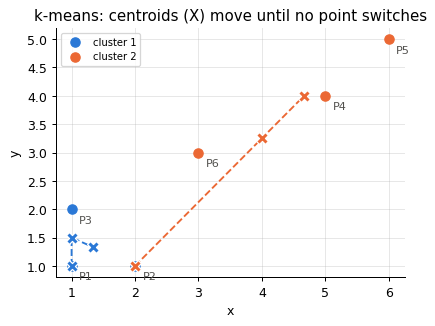

In [10]:
fig, ax = plt.subplots(figsize=(5, 3.6))
for k, (col, name) in enumerate([(BLUE, "cluster 1"), (ORANGE, "cluster 2")]):
    ax.scatter(*P[labels == k].T, s=55, color=col, zorder=3, label=name)
    path = np.array([h[k] for h in history[:3]])              # start -> after iteration 1 -> after iteration 2
    ax.plot(*path.T, "--", color=col, lw=1.5)
    ax.scatter(*path.T, marker="X", s=90, color=col, edgecolor="white", zorder=4)
for i, (px, py) in enumerate(P):
    ax.annotate(f"P{i + 1}", (px, py), textcoords="offset points", xytext=(6, -11), color=GRAY, fontsize=9)
ax.set(title="k-means: centroids (X) move until no point switches", xlabel="x", ylabel="y")
ax.legend(loc="upper left", fontsize=8)
plt.show()

### Try it yourself

1-D points $1, 2, 3, 8, 9, 10$, $k = 2$, starting centroids $c_1 = 1$ and $c_2 = 4$. Give the clusters and centroids after iterations 1 and 2, and the final inertia.

<details><summary>Answer</summary>

Iteration 1: point 3 is closer to 4 (distance 1) than to 1 (distance 2), so the clusters are $\{1, 2\}$ and $\{3, 8, 9, 10\}$, and the centroids become $1.5$ and $7.5$.

Iteration 2: point 3 is now closer to 1.5 (1.5 vs 4.5), so the clusters are $\{1, 2, 3\}$ and $\{8, 9, 10\}$, centroids $2$ and $9$. Iteration 3 changes nothing. Inertia $= (1 + 0 + 1) + (1 + 0 + 1) = 4$.
</details>

**Common mistake:** moving a centroid while you are still assigning points. In standard k-means (Lloyd's algorithm) you first assign **all** points with the old centroids, then update **all** centroids.

## 9. Hierarchical clustering: single vs complete linkage

**What it is:** agglomerative clustering starts with every point as its own cluster and keeps **merging the two closest clusters**. The **linkage** defines the distance between two clusters: **single** = the closest pair of points, **complete** = the farthest pair. **Analogy:** groups forming at a party: with single linkage you join a group if you know *anyone* in it; with complete linkage only if you are close to *everyone* in it.

### Problem

Four shops lie on a straight road at positions (km): A = 0, B = 2, C = 4.5, D = 7.5. Give the merge order and merge heights for single and complete linkage, and the two clusters each method gives.

### Solution by hand

1. Distance matrix:

| | A | B | C | D |
|---|---|---|---|---|
| A | 0 | 2 | 4.5 | 7.5 |
| B | 2 | 0 | 2.5 | 5.5 |
| C | 4.5 | 2.5 | 0 | 3 |
| D | 7.5 | 5.5 | 3 | 0 |

2. **Single linkage** (minimum):
   - Smallest distance A-B = 2: merge $\{A, B\}$ at height **2**.
   - $d(\{A,B\}, C) = \min(4.5, 2.5) = 2.5$; $d(\{A,B\}, D) = \min(7.5, 5.5) = 5.5$; $d(C, D) = 3$. Smallest is 2.5: merge $\{A, B, C\}$ at **2.5**.
   - $d(\{A,B,C\}, D) = \min(7.5, 5.5, 3) = 3$: merge everything at **3**.
3. **Complete linkage** (maximum):
   - First merge is again $\{A, B\}$ at **2**.
   - $d(\{A,B\}, C) = \max(4.5, 2.5) = 4.5$; $d(\{A,B\}, D) = \max(7.5, 5.5) = 7.5$; $d(C, D) = 3$. Smallest is 3: merge $\{C, D\}$ at **3**.
   - $d(\{A,B\}, \{C,D\}) = \max(4.5, 7.5, 2.5, 5.5) = 7.5$: merge everything at **7.5**.
4. Cutting each tree into 2 clusters: single gives $\{A, B, C\}$ and $\{D\}$; complete gives $\{A, B\}$ and $\{C, D\}$. Single linkage "chains" C onto the A-B group through its nearest member B; complete linkage prefers compact groups.

In [11]:
pos = np.array([[0], [2], [4.5], [7.5]])           # A, B, C, D on the road (km)
Z_single = linkage(pos, method="single")
Z_complete = linkage(pos, method="complete")
print("single   linkage merge heights:", Z_single[:, 2])
print("complete linkage merge heights:", Z_complete[:, 2], "\n")
for i, hand in enumerate([2, 2.5, 3]):
    check(f"single linkage, merge {i + 1}", Z_single[i, 2], hand)
for i, hand in enumerate([2, 3, 7.5]):
    check(f"complete linkage, merge {i + 1}", Z_complete[i, 2], hand)

two_single = fcluster(Z_single, t=2, criterion="maxclust")
two_complete = fcluster(Z_complete, t=2, criterion="maxclust")
print("\n2 clusters, single  :", dict(zip("ABCD", two_single.tolist())))
print("2 clusters, complete:", dict(zip("ABCD", two_complete.tolist())))
assert two_single[0] == two_single[1] == two_single[2] != two_single[3]       # {A, B, C} and {D}
assert two_complete[0] == two_complete[1] != two_complete[2] == two_complete[3]  # {A, B} and {C, D}

single   linkage merge heights: [2.  2.5 3. ]
complete linkage merge heights: [2.  3.  7.5] 

single linkage, merge 1                  code =      2.0000   by hand =      2.0000   OK
single linkage, merge 2                  code =      2.5000   by hand =      2.5000   OK
single linkage, merge 3                  code =      3.0000   by hand =      3.0000   OK
complete linkage, merge 1                code =      2.0000   by hand =      2.0000   OK
complete linkage, merge 2                code =      3.0000   by hand =      3.0000   OK
complete linkage, merge 3                code =      7.5000   by hand =      7.5000   OK

2 clusters, single  : {'A': 1, 'B': 1, 'C': 1, 'D': 2}
2 clusters, complete: {'A': 1, 'B': 1, 'C': 2, 'D': 2}


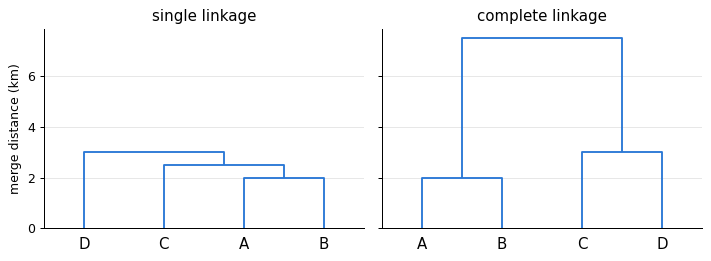

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3), sharey=True)
for ax, Z, name in zip(axes, [Z_single, Z_complete], ["single linkage", "complete linkage"]):
    dendrogram(Z, labels=list("ABCD"), ax=ax, link_color_func=lambda k: BLUE)
    ax.set_title(name)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("merge distance (km)")
plt.tight_layout()
plt.show()

### Try it yourself

Positions A = 0, B = 3, C = 5, D = 9. Give the merge order and heights for single and complete linkage.

<details><summary>Answer</summary>

Both methods first merge B and C at 2.
- Single: $d(A, \{B,C\}) = \min(3, 5) = 3$ beats $d(\{B,C\}, D) = \min(6, 4) = 4$, so A joins at **3**, then D joins at **4**.
- Complete: $d(A, \{B,C\}) = \max(3, 5) = 5$ beats $d(\{B,C\}, D) = \max(6, 4) = 6$, so A joins at **5**, then D joins at $\max(9, 6, 4) = $ **9**.
</details>

**Exam tip:** for single linkage on points along a line, the merge heights are simply the gaps between neighbouring points, in increasing order.

## 10. DBSCAN: core, border and noise points

**What it is:** DBSCAN finds dense regions. A point is a **core** point if at least `min_samples` points (counting itself, in scikit-learn) lie within distance `eps`. Clusters grow from core points; a **border** point is within `eps` of a core point but is not core itself; everything else is **noise**. **Analogy:** towns are dense groups of houses, houses on the edge of town are border points, and lonely farmhouses are noise.

### Problem

1-D points: $1.0, 2.0, 2.8, 3.5, 7.0, 8.0, 8.9, 13.0$ with `eps` $= 1.2$ and `min_samples` $= 3$. Label every point core, border or noise, and give the clusters.

### Solution by hand

1. For each point, list the points within distance $\le 1.2$ (including itself):

| point | neighbours within 1.2 | count | type |
|---|---|---|---|
| 1.0 | 1.0, 2.0 | 2 | border (next to core 2.0) |
| 2.0 | 1.0, 2.0, 2.8 | 3 | **core** |
| 2.8 | 2.0, 2.8, 3.5 | 3 | **core** |
| 3.5 | 2.8, 3.5 | 2 | border (next to core 2.8) |
| 7.0 | 7.0, 8.0 | 2 | border (next to core 8.0) |
| 8.0 | 7.0, 8.0, 8.9 | 3 | **core** |
| 8.9 | 8.0, 8.9 | 2 | border (next to core 8.0) |
| 13.0 | 13.0 | 1 | noise |

   (2.0 and 3.5 are $1.5 > 1.2$ apart, so they are not neighbours.)
2. Core points 2.0 and 2.8 are neighbours, so they are in the same cluster, together with their border points: cluster 1 $= \{1.0, 2.0, 2.8, 3.5\}$. Cluster 2 $= \{7.0, 8.0, 8.9\}$ around core 8.0. Noise $= \{13.0\}$.

In [13]:
pts = np.array([1.0, 2.0, 2.8, 3.5, 7.0, 8.0, 8.9, 13.0])
eps, min_samples = 1.2, 3
counts = np.array([(np.abs(pts - p) <= eps).sum() for p in pts])   # neighbours within eps, including the point
db = DBSCAN(eps=eps, min_samples=min_samples).fit(pts[:, None])
is_core = np.zeros(len(pts), dtype=bool)
is_core[db.core_sample_indices_] = True
kind = np.where(is_core, "core", np.where(db.labels_ == -1, "noise", "border"))
print(pd.DataFrame({"point": pts, "neighbours": counts, "type": kind, "cluster": db.labels_}).to_string(index=False), "\n")
assert pts[is_core].tolist() == [2.0, 2.8, 8.0]
assert pts[db.labels_ == -1].tolist() == [13.0]
check("neighbours of 2.0", counts[1], 3)
check("number of clusters", len(set(db.labels_)) - (1 if -1 in db.labels_ else 0), 2)

 point  neighbours   type  cluster
   1.0           2 border        0
   2.0           3   core        0
   2.8           3   core        0
   3.5           2 border        0
   7.0           2 border        1
   8.0           3   core        1
   8.9           2 border        1
  13.0           1  noise       -1 

neighbours of 2.0                        code =      3.0000   by hand =      3.0000   OK
number of clusters                       code =      2.0000   by hand =      2.0000   OK


### Try it yourself

Same points, but `eps` $= 2.0$ (still `min_samples` $= 3$). Which points are core, and what are the clusters?

<details><summary>Answer</summary>

Every point except 13.0 is now core: for example 1.0 has neighbours 1.0, 2.0, 2.8 (3 points), 3.5 has 2.0, 2.8, 3.5, and 7.0 has 7.0, 8.0, 8.9 (8.9 is 1.9 away). The clusters are still $\{1.0, 2.0, 2.8, 3.5\}$ and $\{7.0, 8.0, 8.9\}$ (3.5 and 7.0 are 3.5 apart), and 13.0 is noise.
</details>

**Exam tip:** read how the question defines `MinPts`: scikit-learn's `min_samples` counts the point itself, some textbooks do not. The same data can give different core points under the two definitions.

## 11. PCA by hand on a 2-D dataset

**What it is:** PCA rotates the axes so that the first new axis (PC1) points along the direction of largest spread, the second along the next largest, and so on. These directions are the **eigenvectors** of the covariance matrix, and the **eigenvalues** are the variances along them. **Analogy:** photographing a long, thin object from the side that shows its full length instead of end-on.

### Problem

Five points: $(4, 3), (5, 1), (6, 6), (7, 7), (8, 8)$. Find the covariance matrix (divide by $n - 1$), its eigenvalues and eigenvectors, the explained variance ratio, and the PC1 scores.

### Solution by hand

1. **Center.** Mean $= (30/5, 25/5) = (6, 5)$. Centered points: $(-2, -2), (-1, -4), (0, 1), (1, 2), (2, 3)$.
2. **Covariance** with $n - 1 = 4$: $\operatorname{var}(x_1) = (4 + 1 + 0 + 1 + 4)/4 = 2.5$; $\operatorname{var}(x_2) = (4 + 16 + 1 + 4 + 9)/4 = 8.5$; $\operatorname{cov} = (4 + 4 + 0 + 2 + 6)/4 = 4$.
$$\Sigma = \begin{pmatrix} 2.5 & 4 \\ 4 & 8.5 \end{pmatrix}$$
3. **Eigenvalues** of a 2x2 matrix solve $\lambda^2 - T\lambda + D = 0$ with trace $T = 2.5 + 8.5 = 11$ and determinant $D = 2.5 \times 8.5 - 4^2 = 21.25 - 16 = 5.25$:
$$\lambda = \frac{T \pm \sqrt{T^2 - 4D}}{2} = \frac{11 \pm \sqrt{121 - 21}}{2} = \frac{11 \pm 10}{2} \;\Rightarrow\; \lambda_1 = 10.5,\; \lambda_2 = 0.5$$
4. **Eigenvectors.** For $\lambda_1$: $(2.5 - 10.5)v_1 + 4v_2 = 0 \Rightarrow v_2 = 2v_1$, so PC1 $= (1, 2)/\sqrt5 = (0.4472, 0.8944)$. For $\lambda_2$: $(2.5 - 0.5)v_1 + 4v_2 = 0 \Rightarrow v_1 = -2v_2$, so PC2 $= (2, -1)/\sqrt5 = (0.8944, -0.4472)$. They are perpendicular: $0.4472 \times 0.8944 - 0.8944 \times 0.4472 = 0$.
5. **Explained variance ratio:** PC1 $= 10.5/(10.5 + 0.5) = 0.9545$, PC2 $= 0.0455$. One direction keeps 95.45% of the spread.
6. **PC1 scores** $z = (\tilde x_1 + 2\tilde x_2)/\sqrt5$: $-6/\sqrt5 = -2.6833$, $-9/\sqrt5 = -4.0249$, $2/\sqrt5 = 0.8944$, $5/\sqrt5 = 2.2361$, $8/\sqrt5 = 3.5777$. Check: their variance is $(36 + 81 + 4 + 25 + 64)/(5 \times 4) = 210/20 = 10.5 = \lambda_1$.

In [14]:
X = np.array([[4, 3], [5, 1], [6, 6], [7, 7], [8, 8]], dtype=float)
mean = X.mean(axis=0)
Xc = X - mean
cov = Xc.T @ Xc / (len(X) - 1)
eigvals, eigvecs = np.linalg.eigh(cov)             # eigh: for symmetric matrices, eigenvalues in ascending order
eigvals, eigvecs = eigvals[::-1], eigvecs[:, ::-1] # largest first
pc1 = eigvecs[:, 0] * np.sign(eigvecs[0, 0])       # an eigenvector's sign is arbitrary: make the first entry positive
scores = Xc @ pc1
print("mean:", mean, "\ncovariance:\n", cov, "\neigenvalues:", eigvals, "\nPC1:", pc1.round(4), "\nPC1 scores:", scores.round(4), "\n")
check("cov(x1, x2)", cov[0, 1], 4.0)
check("lambda 1", eigvals[0], 10.5)
check("lambda 2", eigvals[1], 0.5)
check("PC1 first entry (1/sqrt 5)", pc1[0], 0.4472)
check("explained variance ratio, PC1", eigvals[0] / eigvals.sum(), 0.9545)
check("PC1 score of (5, 1)", scores[1], -4.0249)

pca = PCA(n_components=2).fit(X)
check("sklearn explained_variance_ratio_", pca.explained_variance_ratio_[0], 0.9545)
check("sklearn |PC1| second entry", abs(pca.components_[0, 1]), 0.8944)
check("sklearn |score| of (8, 8)", abs(pca.transform(X)[4, 0]), 3.5777)

mean: [6. 5.] 
covariance:
 [[2.5 4. ]
 [4.  8.5]] 
eigenvalues: [10.5  0.5] 
PC1: [0.4472 0.8944] 
PC1 scores: [-2.6833 -4.0249  0.8944  2.2361  3.5777] 

cov(x1, x2)                              code =      4.0000   by hand =      4.0000   OK
lambda 1                                 code =     10.5000   by hand =     10.5000   OK
lambda 2                                 code =      0.5000   by hand =      0.5000   OK
PC1 first entry (1/sqrt 5)               code =      0.4472   by hand =      0.4472   OK
explained variance ratio, PC1            code =      0.9545   by hand =      0.9545   OK
PC1 score of (5, 1)                      code =     -4.0249   by hand =     -4.0249   OK
sklearn explained_variance_ratio_        code =      0.9545   by hand =      0.9545   OK
sklearn |PC1| second entry               code =      0.8944   by hand =      0.8944   OK
sklearn |score| of (8, 8)                code =      3.5777   by hand =      3.5777   OK


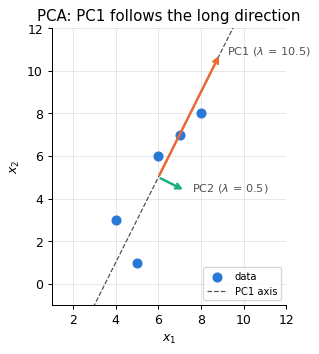

In [15]:
fig, ax = plt.subplots(figsize=(4.6, 4))
ax.scatter(*X.T, s=50, color=BLUE, zorder=3, label="data")
axis_pts = mean + np.outer([-3.2, 3.2], pc1 * np.sqrt(eigvals[0]))   # the PC1 line through the cloud
ax.plot(*axis_pts.T, "--", color=GRAY, lw=1, label="PC1 axis")
for vec, lam, col, name in [(eigvecs[:, 0] * np.sign(eigvecs[0, 0]), eigvals[0], ORANGE, "PC1"),
                            (eigvecs[:, 1] * np.sign(eigvecs[0, 1]), eigvals[1], AQUA, "PC2")]:
    end = mean + 2 * np.sqrt(lam) * vec            # arrow length = 2 standard deviations along that axis
    ax.annotate("", xy=end, xytext=mean, arrowprops=dict(arrowstyle="->", color=col, lw=2))
    ax.text(*end, f"  {name} ($\\lambda$ = {lam:g})", color=GRAY, fontsize=9)
ax.set_aspect("equal")
ax.set(title="PCA: PC1 follows the long direction", xlabel="$x_1$", ylabel="$x_2$", xlim=(1, 12), ylim=(-1, 12))
ax.legend(loc="lower right", fontsize=8)
plt.show()

### Try it yourself

A covariance matrix is $\begin{pmatrix} 3 & 1 \\ 1 & 3 \end{pmatrix}$. Find the eigenvalues, the explained variance ratio of PC1, and the PC1 direction.

<details><summary>Answer</summary>

$T = 6$, $D = 9 - 1 = 8$, so $\lambda = (6 \pm \sqrt{36 - 32})/2 = (6 \pm 2)/2$: $\lambda_1 = 4$, $\lambda_2 = 2$. Ratio $= 4/6 = 0.6667$. For $\lambda_1$: $(3 - 4)v_1 + v_2 = 0 \Rightarrow v_2 = v_1$, so PC1 $= (0.7071, 0.7071)$.
</details>

**Common mistake:** forgetting to center the data before computing the covariance. Using $n$ instead of $n - 1$ changes the eigenvalues but not the eigenvectors or the explained variance ratio.

## 12. EM for a mixture of two Gaussians: one E-step and one M-step

**What it is:** when the data look like two overlapping bell curves, the **EM algorithm** alternates two steps. **E-step:** for every point, compute how much each bell "is responsible" for it (a soft membership between 0 and 1). **M-step:** re-estimate each bell's weight, mean and variance using those soft memberships. **Analogy:** k-means with soft assignments: a point can be 70% in one group and 30% in the other.

### Problem

Data $x = (0, 1, 2, 5, 9)$. Start with $\pi_1 = \pi_2 = 0.5$, $\mu_1 = 2$, $\mu_2 = 6$, $\sigma_1^2 = \sigma_2^2 = 4$. Do one E-step and one M-step.

### Solution by hand

We carry 6 decimals for the responsibilities and the new means, because they get multiplied and squared later.

1. **E-step formula:**
$$r_{i1} = \frac{\pi_1 N(x_i \mid \mu_1, \sigma_1^2)}{\pi_1 N(x_i \mid \mu_1, \sigma_1^2) + \pi_2 N(x_i \mid \mu_2, \sigma_2^2)}, \qquad r_{i2} = 1 - r_{i1}$$
   Here the weights and variances are equal, so the factors $0.5$ and $1/\sqrt{2\pi \cdot 4}$ cancel and only the exponentials remain:
$$r_{i1} = \frac{1}{1 + e^{[(x_i - 2)^2 - (x_i - 6)^2]/8}} = \frac{1}{1 + e^{x_i - 4}} \quad\text{since } (x-2)^2 - (x-6)^2 = 8x - 32.$$
2. **Responsibilities:**

| $x$ | $e^{x-4}$ | $r_1$ | $r_2 = 1 - r_1$ |
|---|---|---|---|
| 0 | 0.0183 | 0.982014 | 0.017986 |
| 1 | 0.0498 | 0.952574 | 0.047426 |
| 2 | 0.1353 | 0.880797 | 0.119203 |
| 5 | 2.7183 | 0.268941 | 0.731059 |
| 9 | 148.4132 | 0.006693 | 0.993307 |

3. **Weights:** $N_1 = \sum r_{i1} = 3.0910$ and $N_2 = 5 - 3.0910 = 1.9090$. So $\pi_1 = 3.0910/5 = 0.6182$ and $\pi_2 = 0.3818$.
4. **Means** $\mu_k = \sum_i r_{ik} x_i / N_k$:
   - $\mu_1 = (0 + 0.9526 + 1.7616 + 1.3447 + 0.0602)/3.0910 = 4.1191/3.0910 = 1.3326$ (1.332606 with full precision).
   - $\mu_2 = (0 + 0.0474 + 0.2384 + 3.6553 + 8.9398)/1.9090 = 12.8809/1.9090 = 6.7475$ (6.747522 with full precision).
5. **Variances** $\sigma_k^2 = \sum_i r_{ik}(x_i - \mu_k)^2 / N_k$, using the **new** means:
   - Deviations from $\mu_1$: $-1.332606, -0.332606, 0.667394, 3.667394, 7.667394$. Terms $r_{i1}(x_i - \mu_1)^2$: $1.7439 + 0.1054 + 0.3923 + 3.6172 + 0.3935 = 6.2523$, so $\sigma_1^2 = 6.2523/3.0910 = 2.0227$.
   - Deviations from $\mu_2$: $-6.747522, -5.747522, -4.747522, -1.747522, 2.252478$. Terms $r_{i2}(x_i - \mu_2)^2$: $0.8189 + 1.5667 + 2.6867 + 2.2325 + 5.0397 = 12.3445$, so $\sigma_2^2 = 12.3445/1.9090 = 6.4665$.
6. **Reading it:** bell 1 moved onto the group $\{0, 1, 2\}$ ($\mu_1$: $2 \to 1.33$) and got narrower; bell 2 moved toward $\{5, 9\}$ ($\mu_2$: $6 \to 6.75$) and got wider, because its two points are far apart. Repeating E and M steps would keep improving the fit.

In [16]:
x = np.array([0, 1, 2, 5, 9], dtype=float)
pi, mu, var = np.array([0.5, 0.5]), np.array([2.0, 6.0]), np.array([4.0, 4.0])

# E-step: responsibilities r[i, k] = pi_k * N(x_i | mu_k, var_k), normalized over k
dens = pi * norm.pdf(x[:, None], mu, np.sqrt(var))
r = dens / dens.sum(axis=1, keepdims=True)
# M-step
Nk = r.sum(axis=0)
pi_new = Nk / len(x)
mu_new = (r * x[:, None]).sum(axis=0) / Nk
var_new = (r * (x[:, None] - mu_new) ** 2).sum(axis=0) / Nk
print(pd.DataFrame({"x": x, "r1": r[:, 0], "r2": r[:, 1]}).to_string(index=False, formatters={"r1": "{:.6f}".format, "r2": "{:.6f}".format}), "\n")
check("r1 for x = 5", r[3, 0], 0.268941, dp=6)
check("N1", Nk[0], 3.0910)
check("pi1", pi_new[0], 0.6182)
check("mu1", mu_new[0], 1.3326)
check("mu2", mu_new[1], 6.7475)
check("var1", var_new[0], 2.0227)
check("var2", var_new[1], 6.4665)

# scikit-learn: start from the same parameters and allow exactly one E-step + M-step
gm = GaussianMixture(n_components=2, weights_init=pi, means_init=mu[:, None],
                     precisions_init=(1 / var)[:, None, None], max_iter=1, reg_covar=0)
with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)   # one iteration is deliberately "not converged"
    gm.fit(x[:, None])
check("sklearn weight 1", gm.weights_[0], 0.6182)
check("sklearn mean 1", gm.means_[0, 0], 1.3326)
check("sklearn variance 2", gm.covariances_[1, 0, 0], 6.4665)

  x       r1       r2
0.0 0.982014 0.017986
1.0 0.952574 0.047426
2.0 0.880797 0.119203
5.0 0.268941 0.731059
9.0 0.006693 0.993307 

r1 for x = 5                             code =    0.268941   by hand =    0.268941   OK
N1                                       code =      3.0910   by hand =      3.0910   OK
pi1                                      code =      0.6182   by hand =      0.6182   OK
mu1                                      code =      1.3326   by hand =      1.3326   OK
mu2                                      code =      6.7475   by hand =      6.7475   OK
var1                                     code =      2.0227   by hand =      2.0227   OK
var2                                     code =      6.4665   by hand =      6.4665   OK
sklearn weight 1                         code =      0.6182   by hand =      0.6182   OK
sklearn mean 1                           code =      1.3326   by hand =      1.3326   OK
sklearn variance 2                       code =      6.4665   by 

### Try it yourself

With the **starting** parameters above, what are the responsibilities $r_1$ of the points $x = 3$ and $x = 6$?

<details><summary>Answer</summary>

$r_1 = 1/(1 + e^{x - 4})$. For $x = 3$: $1/(1 + e^{-1}) = 1/1.3679 = 0.7311$. For $x = 6$: $1/(1 + e^{2}) = 1/8.3891 = 0.1192$.
</details>

**Common mistake:** in the M-step, computing the variances with the *old* means, or dividing by $n$ instead of $N_k$ (the soft count of points in that component).

## 13. Apriori: support, confidence and lift

**What it is:** association rules look for items bought together. **Support** = how often an itemset appears; **confidence** of $X \to Y$ = how often baskets with $X$ also contain $Y$; **lift** = confidence divided by how common $Y$ is anyway. **Apriori** saves work by never counting an itemset that has an infrequent subset. **Analogy:** a shopkeeper noticing that people who buy butter almost always pick up bread too.

### Problem

| Basket | Items |
|---|---|
| T1 | bread, milk |
| T2 | bread, butter, milk |
| T3 | bread, butter |
| T4 | milk, eggs |
| T5 | bread, butter, milk, eggs |

With minimum support 0.4, find the frequent itemsets using Apriori. Then compute confidence and lift for butter $\to$ bread, bread $\to$ milk and $\{$bread, butter$\} \to$ milk.

### Solution by hand

$$\text{supp}(X) = \frac{\#\text{baskets containing } X}{5} \qquad \text{conf}(X \to Y) = \frac{\text{supp}(X \cup Y)}{\text{supp}(X)} \qquad \text{lift}(X \to Y) = \frac{\text{supp}(X \cup Y)}{\text{supp}(X)\,\text{supp}(Y)}$$

1. **Single items:** bread $4/5 = 0.8$, milk $0.8$, butter $0.6$, eggs $0.4$. All reach 0.4, so all are frequent.
2. **Pairs:** bread+milk $3/5 = 0.6$, bread+butter $0.6$, butter+milk $0.4$, milk+eggs $0.4$ are frequent; bread+eggs $0.2$ and butter+eggs $0.2$ are not.
3. **Triples (Apriori pruning):** a triple can only be frequent if all of its pairs are. $\{$bread, butter, milk$\}$: its three pairs are frequent, so count it: T2 and T5, support $0.4$, **frequent**. Every other triple contains bread+eggs or butter+eggs, so it is pruned without counting.
4. **Rules:**

| Rule | confidence | lift |
|---|---|---|
| butter $\to$ bread | $0.6/0.6 = 1.0$ | $0.6/(0.6 \times 0.8) = 1.25$ |
| bread $\to$ milk | $0.6/0.8 = 0.75$ | $0.6/(0.8 \times 0.8) = 0.9375$ |
| $\{$bread, butter$\} \to$ milk | $0.4/0.6 = 0.6667$ | $0.4/(0.6 \times 0.8) = 0.8333$ |

5. **Reading lift:** above 1 means "more likely than usual" (every butter buyer took bread). Below 1 means "less likely than usual": bread $\to$ milk has a high confidence of 0.75, but milk is in 80% of all baskets anyway, so bread buyers are actually slightly *less* likely to buy milk.

In [17]:
baskets = [{"bread", "milk"}, {"bread", "butter", "milk"}, {"bread", "butter"},
           {"milk", "eggs"}, {"bread", "butter", "milk", "eggs"}]
items = ["bread", "milk", "butter", "eggs"]
onehot = pd.DataFrame([[item in b for item in items] for b in baskets],
                      columns=items, index=["T1", "T2", "T3", "T4", "T5"]).astype(int)
print(onehot, "\n")

def support(*itemset):
    return onehot[list(itemset)].all(axis=1).mean()

# Counting every itemset gives the same frequent sets; Apriori just skips the ones it can rule out early
frequent = [s for k in (1, 2, 3) for s in combinations(items, k) if support(*s) >= 0.4]
print("frequent itemsets:", frequent, "\n")
assert len(frequent) == 9

def confidence(X, Y): return support(*X, *Y) / support(*X)
def lift(X, Y): return support(*X, *Y) / (support(*X) * support(*Y))

check("support(bread, butter, milk)", support("bread", "butter", "milk"), 0.4)
check("conf(butter -> bread)", confidence(["butter"], ["bread"]), 1.0)
check("lift(butter -> bread)", lift(["butter"], ["bread"]), 1.25)
check("conf(bread -> milk)", confidence(["bread"], ["milk"]), 0.75)
check("lift(bread -> milk)", lift(["bread"], ["milk"]), 0.9375)
check("conf({bread, butter} -> milk)", confidence(["bread", "butter"], ["milk"]), 0.6667)
check("lift({bread, butter} -> milk)", lift(["bread", "butter"], ["milk"]), 0.8333)

    bread  milk  butter  eggs
T1      1     1       0     0
T2      1     1       1     0
T3      1     0       1     0
T4      0     1       0     1
T5      1     1       1     1 

frequent itemsets: [('bread',), ('milk',), ('butter',), ('eggs',), ('bread', 'milk'), ('bread', 'butter'), ('milk', 'butter'), ('milk', 'eggs'), ('bread', 'milk', 'butter')] 

support(bread, butter, milk)             code =      0.4000   by hand =      0.4000   OK
conf(butter -> bread)                    code =      1.0000   by hand =      1.0000   OK
lift(butter -> bread)                    code =      1.2500   by hand =      1.2500   OK
conf(bread -> milk)                      code =      0.7500   by hand =      0.7500   OK
lift(bread -> milk)                      code =      0.9375   by hand =      0.9375   OK
conf({bread, butter} -> milk)            code =      0.6667   by hand =      0.6667   OK
lift({bread, butter} -> milk)            code =      0.8333   by hand =      0.8333   OK


### Try it yourself

Using the same 5 baskets, compute the confidence and lift of milk $\to$ eggs and of eggs $\to$ milk.

<details><summary>Answer</summary>

milk $\to$ eggs: confidence $0.4/0.8 = 0.5$, lift $0.4/(0.8 \times 0.4) = 1.25$. eggs $\to$ milk: confidence $0.4/0.4 = 1.0$, lift $1.25$.
</details>

**Exam tip:** lift is symmetric (lift of $X \to Y$ equals lift of $Y \to X$); confidence is not.

---
**Part D: Anomaly detection**

## 14. Gaussian anomaly detection and choosing $\varepsilon$ by F1

**What it is:** fit a bell curve to each feature using **normal** examples only, multiply the per-feature densities to get $p(x)$, and flag a new example as an **anomaly** when $p(x) < \varepsilon$. **Analogy:** a doctor knows the usual ranges of heart rate and temperature; a patient far outside both is worth a closer look.

### Problem

Six readings from healthy machines: $x_1$ = vibration (mm/s), $x_2$ = temperature (°C).

| reading | 1 | 2 | 3 | 4 | 5 | 6 |
|---|---|---|---|---|---|---|
| $x_1$ | 3 | 6 | 6 | 5 | 5 | 5 |
| $x_2$ | 20 | 23 | 18 | 21 | 17 | 21 |

1. Estimate $\mu_j$ and $\sigma_j^2$ for each feature (divide by $m$).
2. Compute $p(x)$ for A $= (5.5, 21)$ and B $= (8, 25)$ and flag them with $\varepsilon = 0.001$.
3. Choose $\varepsilon$ from $\{0.0005, 0.001, 0.01, 0.02\}$ with the best F1 on this labelled cross-validation set ($p(x)$ already computed with the model; $y = 1$ means a real failure):

| $p(x)$ | 0.08 | 0.05 | 0.03 | 0.012 | 0.006 | 0.0009 | 0.0004 | 0.00002 |
|---|---|---|---|---|---|---|---|---|
| $y$ | 0 | 0 | 0 | 0 | 1 | 0 | 1 | 1 |

### Solution by hand

$$p(x) = \prod_j N(x_j;\, \mu_j, \sigma_j^2), \qquad N(x;\, \mu, \sigma^2) = \frac{1}{\sqrt{2\pi\sigma^2}}\, e^{-(x-\mu)^2/(2\sigma^2)}$$

Densities get small, so this section uses 6 decimals.

1. $\mu_1 = 30/6 = 5$, $\sigma_1^2 = (4 + 1 + 1 + 0 + 0 + 0)/6 = 1$. $\mu_2 = 120/6 = 20$, $\sigma_2^2 = (0 + 9 + 4 + 1 + 9 + 1)/6 = 24/6 = 4$.
2. Constants: $1/\sqrt{2\pi \cdot 1} = 0.398942$ and $1/\sqrt{2\pi \cdot 4} = 0.199471$.
3. **A = (5.5, 21):** exponents $0.5^2/2 = 0.125$ and $1^2/8 = 0.125$, and $e^{-0.125} = 0.882497$.
   $N_1 = 0.398942 \times 0.882497 = 0.352065$, $N_2 = 0.199471 \times 0.882497 = 0.176033$, so $p(A) = 0.352065 \times 0.176033 = 0.061975 > 0.001$: **normal**.
4. **B = (8, 25):** exponents $3^2/2 = 4.5$ and $5^2/8 = 3.125$; $e^{-4.5} = 0.011109$ and $e^{-3.125} = 0.043937$.
   $N_1 = 0.398942 \times 0.011109 = 0.004432$, $N_2 = 0.199471 \times 0.043937 = 0.008764$, so $p(B) = 0.004432 \times 0.008764 = 3.884 \times 10^{-5} < 0.001$: **anomaly**.
5. **Choosing $\varepsilon$** (flag when $p < \varepsilon$; $F_1 = 2TP/(2TP + FP + FN)$):

| $\varepsilon$ | flagged | TP | FP | FN | precision | recall | F1 |
|---|---|---|---|---|---|---|---|
| 0.0005 | 0.0004, 0.00002 | 2 | 0 | 1 | 1.0 | 0.6667 | 0.8 |
| 0.001 | + 0.0009 | 2 | 1 | 1 | 0.6667 | 0.6667 | 0.6667 |
| 0.01 | + 0.006 | 3 | 1 | 0 | 0.75 | 1.0 | **0.8571** |
| 0.02 | + 0.012 | 3 | 2 | 0 | 0.6 | 1.0 | 0.75 |

   The best choice is $\varepsilon = 0.01$ with $F_1 = 6/7 = 0.8571$.

In [18]:
train = np.array([[3, 20], [6, 23], [6, 18], [5, 21], [5, 17], [5, 21]], dtype=float)
mu = train.mean(axis=0)
var = train.var(axis=0)                            # divide by m (ddof=0), as in the hand solution
check("mu1", mu[0], 5)
check("var1", var[0], 1)
check("mu2", mu[1], 20)
check("var2", var[1], 4)

def p(x):
    return np.prod(norm.pdf(x, mu, np.sqrt(var)))  # product of the per-feature densities

pA, pB = p([5.5, 21]), p([8, 25])
check("p(A)", pA, 0.061975, dp=6)
check("p(B) x 10^5", pB * 1e5, 3.884, dp=3)
eps = 0.001
print(f"A: p = {pA:.6f} -> {'anomaly' if pA < eps else 'normal'};   B: p = {pB:.3e} -> {'anomaly' if pB < eps else 'normal'}\n")

p_cv = np.array([0.08, 0.05, 0.03, 0.012, 0.006, 0.0009, 0.0004, 0.00002])
y_cv = np.array([0, 0, 0, 0, 1, 0, 1, 1])
f1s = {e: f1_score(y_cv, (p_cv < e).astype(int)) for e in [0.0005, 0.001, 0.01, 0.02]}
print("F1 for each epsilon:", {e: round(float(f), 4) for e, f in f1s.items()})
best = max(f1s, key=f1s.get)
check("best epsilon", best, 0.01)
check("best F1 (= 6/7)", f1s[best], 0.8571)

mu1                                      code =      5.0000   by hand =      5.0000   OK
var1                                     code =      1.0000   by hand =      1.0000   OK
mu2                                      code =     20.0000   by hand =     20.0000   OK
var2                                     code =      4.0000   by hand =      4.0000   OK
p(A)                                     code =    0.061975   by hand =    0.061975   OK
p(B) x 10^5                              code =       3.884   by hand =       3.884   OK
A: p = 0.061975 -> normal;   B: p = 3.884e-05 -> anomaly

F1 for each epsilon: {0.0005: 0.8, 0.001: 0.6667, 0.01: 0.8571, 0.02: 0.75}
best epsilon                             code =      0.0100   by hand =      0.0100   OK
best F1 (= 6/7)                          code =      0.8571   by hand =      0.8571   OK


### Try it yourself

With the same model, compute $p(x)$ for C $= (4, 18)$. Is it flagged with $\varepsilon = 0.01$?

<details><summary>Answer</summary>

Exponents: $(4-5)^2/2 = 0.5$ and $(18-20)^2/8 = 0.5$, and $e^{-0.5} = 0.606531$. $N_1 = 0.398942 \times 0.606531 = 0.241971$, $N_2 = 0.199471 \times 0.606531 = 0.120985$, so $p(C) = 0.241971 \times 0.120985 = 0.029275$. That is above 0.01, so C is **normal**.
</details>

**Common mistake:** choosing $\varepsilon$ by accuracy. With very few anomalies, flagging nothing already scores high accuracy (see the imbalanced-data section of [Part 1](00c_ml_numericals_solved_by_hand.ipynb)); use F1, precision and recall.

---
**Part E: Recommender systems**

## 15. Content-based prediction and the collaborative-filtering cost

**What it is:** a rating is predicted as $w^{(j)} \cdot x^{(i)} + b^{(j)}$, where $x^{(i)}$ describes movie $i$ and $w^{(j)}, b^{(j)}$ describe user $j$'s taste. In **content-based** filtering $x$ comes from known item features (genre, price). In **collaborative filtering** both the movie features and the user parameters are **learned from the ratings** themselves. **Analogy:** a friend who knows how much you like romance and action, and how much of each a film contains.

### Problem

(a) **Content-based:** a user has taste $w = (5, 1)$ for (romance, action) and $b = 0.5$. A movie has $x = (0.8, 0.3)$. Predict the rating.

(b) **Collaborative filtering:** ratings (? = not rated) and the current parameters:

| | U1 | U2 | U3 | movie features $x^{(i)}$ |
|---|---|---|---|---|
| M1 | 5 | 4 | ? | (1, 0) |
| M2 | ? | 2 | 1 | (0, 1) |
| M3 | 4 | ? | 5 | (1, 1) |

Users: $w^{(1)} = (4, 1), b^{(1)} = 0.5$; $w^{(2)} = (3, 2), b^{(2)} = 0$; $w^{(3)} = (1, 4), b^{(3)} = -0.5$. With $\lambda = 0.1$ compute
$$J = \frac12\sum_{(i,j):\, r(i,j)=1}\left(w^{(j)}\cdot x^{(i)} + b^{(j)} - y^{(i,j)}\right)^2 + \frac\lambda2\sum_j \lVert w^{(j)}\rVert^2 + \frac\lambda2\sum_i \lVert x^{(i)}\rVert^2,$$
the gradient $\partial J/\partial w^{(1)}_1$, and one gradient step with $\alpha = 0.1$.

(c) **Binary (like / not) version:** like $= 1$ if the rating is $\ge 4$, else 0. With $f = \sigma(w \cdot x + b)$ and the parameters $w^{(1)} = (2, 0), b^{(1)} = 0$; $w^{(2)} = (1, -1), b^{(2)} = 0$; $w^{(3)} = (-1, 1), b^{(3)} = -1$ (same $x$), compute the log-loss cost summed over the rated cells (no regularization).

### Solution by hand

1. **(a)** $5 \times 0.8 + 1 \times 0.3 + 0.5 = 4 + 0.3 + 0.5 = 4.8$.
2. **(b) Predictions and errors** on the 6 rated cells:

| cell | prediction $w \cdot x + b$ | rating | error |
|---|---|---|---|
| M1, U1 | $4 \cdot 1 + 1 \cdot 0 + 0.5 = 4.5$ | 5 | -0.5 |
| M1, U2 | $3 \cdot 1 + 2 \cdot 0 + 0 = 3$ | 4 | -1 |
| M2, U2 | $3 \cdot 0 + 2 \cdot 1 + 0 = 2$ | 2 | 0 |
| M2, U3 | $1 \cdot 0 + 4 \cdot 1 - 0.5 = 3.5$ | 1 | 2.5 |
| M3, U1 | $4 + 1 + 0.5 = 5.5$ | 4 | 1.5 |
| M3, U3 | $1 + 4 - 0.5 = 4.5$ | 5 | -0.5 |

3. Squared errors: $0.25 + 1 + 0 + 6.25 + 2.25 + 0.25 = 10$, so the data term is $\frac12 \times 10 = 5$.
4. Regularization: $\sum\lVert w\rVert^2 = (16 + 1) + (9 + 4) + (1 + 16) = 47$, giving $0.05 \times 47 = 2.35$; $\sum\lVert x\rVert^2 = 1 + 1 + 2 = 4$, giving $0.05 \times 4 = 0.2$. **$J = 5 + 2.35 + 0.2 = 7.55$.**
5. **Gradient for one parameter**, user 1's first weight. Only the movies user 1 rated (M1 and M3) count:
$$\frac{\partial J}{\partial w^{(1)}_1} = \sum_{i:\, r(i,1)=1} \text{error}_{i1}\, x^{(i)}_1 + \lambda w^{(1)}_1 = (-0.5)(1) + (1.5)(1) + 0.1 \times 4 = 1.0 + 0.4 = 1.4$$
   One step: $w^{(1)}_1 \leftarrow 4 - 0.1 \times 1.4 = 3.86$.
6. **(c) Binary version.** Labels: M1U1 = 1, M1U2 = 1, M2U2 = 0, M2U3 = 0, M3U1 = 1, M3U3 = 1. For $y = 1$ the loss is $\ln(1 + e^{-z})$; for $y = 0$ it is $\ln(1 + e^{z})$:

| cell | $z = w \cdot x + b$ | $y$ | loss |
|---|---|---|---|
| M1, U1 | 2 | 1 | $\ln(1 + e^{-2}) = 0.1269$ |
| M1, U2 | 1 | 1 | $\ln(1 + e^{-1}) = 0.3133$ |
| M2, U2 | -1 | 0 | $\ln(1 + e^{-1}) = 0.3133$ |
| M2, U3 | 0 | 0 | $\ln 2 = 0.6931$ |
| M3, U1 | 2 | 1 | $0.1269$ |
| M3, U3 | -1 | 1 | $\ln(1 + e^{1}) = 1.3133$ |

   Cost $= 0.1269 + 0.3133 + 0.3133 + 0.6931 + 0.1269 + 1.3133 = 2.8868$. The biggest share comes from M3, U3: the model gives a liked movie a low score.

In [19]:
check("content-based w.x + b", np.array([5, 1]) @ np.array([0.8, 0.3]) + 0.5, 4.8)

Y = np.array([[5, 4, np.nan], [np.nan, 2, 1], [4, np.nan, 5]])   # rows = movies, columns = users
rated = ~np.isnan(Y)
X = np.array([[1, 0], [0, 1], [1, 1]], dtype=float)                # movie features x^(i)
W = np.array([[4, 1], [3, 2], [1, 4]], dtype=float)                # user weights w^(j)
b = np.array([0.5, 0, -0.5])                                       # user biases b^(j)
lam = 0.1

def cf_cost(X, W, b):
    err = np.where(rated, X @ W.T + b - np.nan_to_num(Y), 0)       # errors on rated cells only
    return 0.5 * (err ** 2).sum() + lam / 2 * (W ** 2).sum() + lam / 2 * (X ** 2).sum(), err

J, err = cf_cost(X, W, b)
print("errors (0 where not rated):\n", err, "\n")
check("CF cost J", J, 7.55)
grad_w11 = (err[:, 0] * X[:, 0]).sum() + lam * W[0, 0]
check("dJ/dw(1)_1", grad_w11, 1.4)
step = 1e-6                                                         # numerical check: nudge w(1)_1 up and down
Wp, Wm = W.copy(), W.copy()
Wp[0, 0] += step
Wm[0, 0] -= step
check("finite-difference dJ/dw(1)_1", (cf_cost(X, Wp, b)[0] - cf_cost(X, Wm, b)[0]) / (2 * step), 1.4)
check("w(1)_1 after one step", W[0, 0] - 0.1 * grad_w11, 3.86)

# Binary (like / not) version with its own parameters
like = np.where(rated, (np.nan_to_num(Y) >= 4).astype(float), np.nan)
Wb = np.array([[2, 0], [1, -1], [-1, 1]], dtype=float)
bb = np.array([0, 0, -1.0])
z = X @ Wb.T + bb
loss = -(like * np.log(expit(z)) + (1 - like) * np.log(1 - expit(z)))   # NaN on unrated cells
check("binary CF cost (sum over rated)", np.nansum(loss), 2.8868)

content-based w.x + b                    code =      4.8000   by hand =      4.8000   OK
errors (0 where not rated):
 [[-0.5 -1.   0. ]
 [ 0.   0.   2.5]
 [ 1.5  0.  -0.5]] 

CF cost J                                code =      7.5500   by hand =      7.5500   OK
dJ/dw(1)_1                               code =      1.4000   by hand =      1.4000   OK
finite-difference dJ/dw(1)_1             code =      1.4000   by hand =      1.4000   OK
w(1)_1 after one step                    code =      3.8600   by hand =      3.8600   OK
binary CF cost (sum over rated)          code =      2.8868   by hand =      2.8868   OK


### Try it yourself

For the squared-error cost in (b), compute $\partial J/\partial x^{(2)}_2$, the gradient for movie 2's second feature.

<details><summary>Answer</summary>

Movie 2 was rated by U2 (error 0) and U3 (error 2.5). $\partial J/\partial x^{(2)}_2 = 0 \times w^{(2)}_2 + 2.5 \times w^{(3)}_2 + \lambda x^{(2)}_2 = 0 \times 2 + 2.5 \times 4 + 0.1 \times 1 = 10.1$.
</details>

**Common mistake:** treating the missing ratings as zeros. Only the rated cells, where $r(i, j) = 1$, enter the sums.

## 16. Mean normalization for new users

**What it is:** subtract each movie's average rating before learning, and add it back when predicting. Then a brand-new user, about whom nothing is known, gets each movie's average instead of 0 stars. **Analogy:** when you know nothing about a new guest's taste, recommend what is popular.

### Problem

Use the ratings matrix from Section 15.
1. Compute each movie's mean over its **rated** entries and the normalized matrix.
2. A new user U4 has no ratings, so regularization drives $w^{(4)} = (0, 0)$ and $b^{(4)} = 0$. Predict U4's ratings with and without mean normalization.
3. The normalized model predicts $w^{(2)} \cdot x^{(3)} + b^{(2)} = 0.3$ for U2 on M3. What is the rating prediction?

### Solution by hand

1. Means: M1 $(5 + 4)/2 = 4.5$; M2 $(2 + 1)/2 = 1.5$; M3 $(4 + 5)/2 = 4.5$. Normalized ratings $y - \mu_i$:

| | U1 | U2 | U3 |
|---|---|---|---|
| M1 | 0.5 | -0.5 | ? |
| M2 | ? | 0.5 | -0.5 |
| M3 | -0.5 | ? | 0.5 |

2. Without normalization: $0 \cdot x + 0 = 0$ stars for every movie (useless). With normalization: $0 + \mu_i$, so U4 gets $4.5, 1.5, 4.5$.
3. $0.3 + \mu_3 = 0.3 + 4.5 = 4.8$.

In [20]:
mu_movie = np.nanmean(Y, axis=1)                   # mean over rated entries only
Y_norm = Y - mu_movie[:, None]
print("movie means:", mu_movie, "\nnormalized ratings:\n", Y_norm, "\n")
check("mean of M1", mu_movie[0], 4.5)
check("mean of M2", mu_movie[1], 1.5)
check("normalized M1, U2", Y_norm[0, 1], -0.5)

w_new, b_new = np.zeros(2), 0.0                    # a user without ratings ends up with zero parameters
pred_new = X @ w_new + b_new + mu_movie
check("new user, M2", pred_new[1], 1.5)
check("U2 on M3 (0.3 + mean)", 0.3 + mu_movie[2], 4.8)
wrong = np.nan_to_num(Y).mean(axis=1)              # the classic mistake: missing ratings counted as 0
print("\nwrong means (missing counted as 0):", wrong)
check("wrong mean of M1", wrong[0], 3.0)

movie means: [4.5 1.5 4.5] 
normalized ratings:
 [[ 0.5 -0.5  nan]
 [ nan  0.5 -0.5]
 [-0.5  nan  0.5]] 

mean of M1                               code =      4.5000   by hand =      4.5000   OK
mean of M2                               code =      1.5000   by hand =      1.5000   OK
normalized M1, U2                        code =     -0.5000   by hand =     -0.5000   OK
new user, M2                             code =      1.5000   by hand =      1.5000   OK
U2 on M3 (0.3 + mean)                    code =      4.8000   by hand =      4.8000   OK

wrong means (missing counted as 0): [3. 1. 3.]
wrong mean of M1                         code =      3.0000   by hand =      3.0000   OK


### Try it yourself

Ratings for 2 movies by 3 users: M1 $= (2, 4, ?)$ and M2 $= (5, ?, 3)$. Give the movie means, the normalized matrix, and the predictions for a new user.

<details><summary>Answer</summary>

Means: M1 $= 3$, M2 $= 4$. Normalized: M1 $= (-1, 1, ?)$, M2 $= (1, ?, -1)$. A new user is predicted 3 for M1 and 4 for M2.
</details>

**Common mistake:** averaging with the missing entries counted as 0: M1 above would get $(5 + 4 + 0)/3 = 3$ instead of 4.5.

---
**Part F: Reinforcement learning**

## 17. Discounted return on a 1-D line of states

**What it is:** an agent moves along a line of states and collects rewards. The **return** adds up the rewards it will get, each multiplied by $\gamma$ once per step of delay: $G = R_1 + \gamma R_2 + \gamma^2 R_3 + \dots$ The **discount factor** $\gamma$ (between 0 and 1) says how much future rewards count. **Analogy:** money now is worth more than the same money next year; $\gamma$ is how patient you are.

### Problem

A robot moves on a line of 6 states. State 1 (a charging dock) gives reward 80 and state 6 (a small battery pack) gives 30; both end the episode. States 2 to 5 give 0. $\gamma = 0.6$. Our convention: the return includes the reward of the starting state and of every state visited until the episode ends.

| state | 1 | 2 | 3 | 4 | 5 | 6 |
|---|---|---|---|---|---|---|
| reward $R(s)$ | 80 (end) | 0 | 0 | 0 | 0 | 30 (end) |

1. What is the return from each state for the policy "always go left", and for "always go right"?
2. What is the best action in each of the states 2 to 5?
3. Starting in state 4 and going left, the rewards are $0, 0, 0, 80$. Compute the return directly.

### Solution by hand

1. From state $s$, going left reaches state 1 after $s - 1$ steps: $G = \gamma^{s-1} \times 80$. Going right reaches state 6 after $6 - s$ steps: $G = \gamma^{6-s} \times 30$. Powers: $\gamma = 0.6$, $\gamma^2 = 0.36$, $\gamma^3 = 0.216$, $\gamma^4 = 0.1296$.

| state | 2 | 3 | 4 | 5 |
|---|---|---|---|---|
| always left | $0.6 \times 80 = 48$ | $0.36 \times 80 = 28.8$ | $0.216 \times 80 = 17.28$ | $0.1296 \times 80 = 10.368$ |
| always right | $0.1296 \times 30 = 3.888$ | $0.216 \times 30 = 6.48$ | $0.36 \times 30 = 10.8$ | $0.6 \times 30 = 18$ |
| best action | left | left | left | **right** |

   (In the end states the episode is already over: $G = 80$ in state 1 and $G = 30$ in state 6.)
2. Left is better in states 2, 3 and 4; in state 5 the small reward one step away (18) beats the big reward four steps away (10.368).
3. $G = 0 + 0.6 \times 0 + 0.36 \times 0 + 0.216 \times 80 = 17.28$, the same as the table.

In [21]:
gamma = 0.6
R = np.array([80, 0, 0, 0, 0, 30], dtype=float)
states = np.arange(1, 7)

def episode_return(start, step):                   # step = -1 (always left) or +1 (always right)
    s, G, discount = start, 0.0, 1.0
    while True:
        G += discount * R[s - 1]
        if s in (1, 6):                            # end state: the episode stops
            return G
        s, discount = s + step, discount * gamma

left = np.array([episode_return(s, -1) for s in states])
right = np.array([episode_return(s, +1) for s in states])
best = ["(end)" if s in (1, 6) else ("left" if l > r else "right") for s, l, r in zip(states, left, right)]
print(pd.DataFrame({"state": states, "always left": left, "always right": right, "best": best}).to_string(index=False), "\n")
check("G(state 4, always left)", left[3], 17.28, dp=2)
check("G(state 5, always left)", left[4], 10.368, dp=3)
check("G(state 2, always right)", right[1], 3.888, dp=3)
check("G(state 5, always right)", right[4], 18)
assert best[1:5] == ["left", "left", "left", "right"]

 state  always left  always right  best
     1       80.000        80.000 (end)
     2       48.000         3.888  left
     3       28.800         6.480  left
     4       17.280        10.800  left
     5       10.368        18.000 right
     6       30.000        30.000 (end) 

G(state 4, always left)                  code =       17.28   by hand =       17.28   OK
G(state 5, always left)                  code =      10.368   by hand =      10.368   OK
G(state 2, always right)                 code =       3.888   by hand =       3.888   OK
G(state 5, always right)                 code =     18.0000   by hand =     18.0000   OK


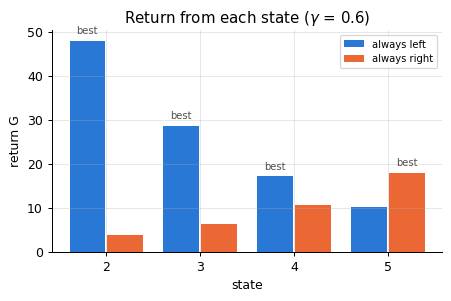

In [22]:
fig, ax = plt.subplots(figsize=(5.6, 3.2))
s_mid = states[1:5]
ax.bar(s_mid - 0.2, left[1:5], width=0.38, color=BLUE, label="always left")
ax.bar(s_mid + 0.2, right[1:5], width=0.38, color=ORANGE, label="always right")
for s, l, r in zip(s_mid, left[1:5], right[1:5]):
    ax.text(s - 0.2 if l > r else s + 0.2, max(l, r) + 1.5, "best", ha="center", color=GRAY, fontsize=8)
ax.set(title=r"Return from each state ($\gamma$ = 0.6)", xlabel="state", ylabel="return G", xticks=s_mid)
ax.legend(fontsize=8)
plt.show()

### Try it yourself

Same line but with a more patient robot, $\gamma = 0.9$. What is the best action in state 5 now?

<details><summary>Answer</summary>

Left: $0.9^4 \times 80 = 0.6561 \times 80 = 52.488$. Right: $0.9 \times 30 = 27$. Now **left** is better: a patient agent is willing to walk further for the bigger reward.
</details>

**Exam tip:** check which convention the question uses. Here (as in several popular courses) the return starts with the reward of the current state; many textbooks instead start with the reward received *after* the first action, $G_t = r_{t+1} + \gamma r_{t+2} + \dots$

## 18. Bellman equation, value iteration and policy iteration

**What it is:** $Q(s, a)$ is the return if you take action $a$ in state $s$ and then behave optimally. The **Bellman equation** writes it recursively: $Q(s, a) = R(s) + \gamma \max_{a'} Q(s', a')$, where $s'$ is the next state. **Value iteration** applies this update to every state again and again; **policy iteration** alternates "evaluate the current policy" and "improve it greedily". **Analogy:** planning a route backwards from the destination: first you know the last turn, then the turn before it, and so on.

### Problem

1. For the line of Section 17 ($\gamma = 0.6$), fill in $Q(s, \text{left})$ and $Q(s, \text{right})$ for states 2 to 5.
2. A tiny deterministic MDP with states S1, S2, S3 and an end state T ($V(T) = 0$), $\gamma = 0.9$, rewards on the transitions:

| state | action | next state | reward |
|---|---|---|---|
| S1 | collect | T | 2 |
| S1 | right | S2 | 0 |
| S2 | left | S1 | 0 |
| S2 | right | S3 | -1 |
| S3 | exit | T | 10 |
| S3 | left | S2 | 0 |

   Do two sweeps of value iteration $V_{k+1}(s) = \max_a [r(s, a) + \gamma V_k(s')]$, starting from $V_0 = 0$.
3. Do one round of policy iteration starting from the policy (collect, left, exit).

### Solution by hand

1. **Q-values on the line.** The best returns from Section 17 are $V^*(1..6) = (80, 48, 28.8, 17.28, 18, 30)$, and $R(s) = 0$ for states 2 to 5, so $Q(s, a) = 0.6\, V^*(s')$:

| state | 2 | 3 | 4 | 5 |
|---|---|---|---|---|
| $Q(s, \text{left})$ | $0.6 \times 80 = 48$ | $0.6 \times 48 = 28.8$ | $0.6 \times 28.8 = 17.28$ | $0.6 \times 17.28 = 10.368$ |
| $Q(s, \text{right})$ | $0.6 \times 28.8 = 17.28$ | $0.6 \times 17.28 = 10.368$ | $0.6 \times 18 = 10.8$ | $0.6 \times 30 = 18$ |

   Note $Q(2, \text{right}) = 17.28$, much more than "always right" (3.888): after one step right, the robot is allowed to turn around and act optimally.
2. **Value iteration** (synchronous: every update in a sweep uses the values from the previous sweep):
   - Sweep 1, from $V_0 = (0, 0, 0)$: S1 $= \max(2,\; 0 + 0.9 \cdot 0) = 2$; S2 $= \max(0 + 0.9 \cdot 0,\; -1 + 0.9 \cdot 0) = 0$; S3 $= \max(10,\; 0 + 0.9 \cdot 0) = 10$. So $V_1 = (2, 0, 10)$.
   - Sweep 2, from $V_1$: S1 $= \max(\text{collect } 2,\; \text{right } 0.9 \times 0 = 0) = 2$; S2 $= \max(\text{left } 0.9 \times 2 = 1.8,\; \text{right } -1 + 0.9 \times 10 = 8) = 8$; S3 $= \max(\text{exit } 10,\; \text{left } 0.9 \times 0 = 0) = 10$. So $V_2 = (2, 8, 10)$; the winning actions were collect, right, exit.
   - The code continues: sweep 3 gives S1 $= \max(2,\; 0.9 \times 8 = 7.2) = 7.2$, so S1 switches to "right"; sweep 4 changes nothing. $V^* = (7.2, 8, 10)$ with policy (right, right, exit). Each sweep lets the reward of 10 travel one state further back.
3. **Policy iteration, one round.** Evaluate $\pi_0 = $ (collect, left, exit) with no max, just following the policy: $V(S1) = 2$, $V(S3) = 10$, $V(S2) = 0 + 0.9 \times V(S1) = 1.8$. Improve greedily: S1: collect 2 vs right $0.9 \times 1.8 = 1.62$, keep collect; S2: left $0.9 \times 2 = 1.8$ vs right $-1 + 0.9 \times 10 = 8$, switch to **right**; S3: exit 10 vs left $1.62$, keep exit. New policy $\pi_1 = $ (collect, right, exit). Two more rounds (in the code) reach (right, right, exit).

In [23]:
V_line = np.maximum(left, right)                   # V*(s) from Section 17 (heading straight to one end is optimal here)
Q_left = gamma * V_line[0:4]                       # states 2..5 have R(s) = 0; next state is s - 1
Q_right = gamma * V_line[2:6]                      # next state is s + 1
print(pd.DataFrame({"state": [2, 3, 4, 5], "Q(s, left)": Q_left, "Q(s, right)": Q_right}).to_string(index=False), "\n")
check("Q(2, right)", Q_right[0], 17.28, dp=2)
check("Q(4, right)", Q_right[2], 10.8, dp=1)
check("Q(5, left)", Q_left[3], 10.368, dp=3)

# Tiny MDP: mdp[state][action] = (next state, or None for the end state, reward)
mdp = {"S1": {"collect": (None, 2), "right": ("S2", 0)},
       "S2": {"left": ("S1", 0), "right": ("S3", -1)},
       "S3": {"exit": (None, 10), "left": ("S2", 0)}}
g = 0.9

def q_value(V, s, a):
    nxt, reward = mdp[s][a]
    return reward + g * (V[nxt] if nxt else 0.0)

V, history = {s: 0.0 for s in mdp}, []
for sweep in range(1, 5):
    winners = {s: max(mdp[s], key=lambda a: q_value(V, s, a)) for s in mdp}   # uses the OLD values
    V = {s: q_value(V, s, winners[s]) for s in mdp}
    history.append(V)
    print(f"value iteration sweep {sweep}: V = {[round(v, 4) for v in V.values()]}, winning actions = {list(winners.values())}")
check("sweep 1: V(S1)", history[0]["S1"], 2)
check("sweep 2: V(S2)", history[1]["S2"], 8)
check("sweep 3: V(S1)", history[2]["S1"], 7.2)
assert history[3] == history[2]                    # converged

def evaluate(policy, sweeps=200):                  # policy evaluation: follow the policy, no max
    V = {s: 0.0 for s in mdp}
    for _ in range(sweeps):
        V = {s: q_value(V, s, policy[s]) for s in mdp}
    return V

policy = {"S1": "collect", "S2": "left", "S3": "exit"}
print()
for round_ in range(1, 5):
    V_pi = evaluate(policy)
    improved = {s: max(mdp[s], key=lambda a: q_value(V_pi, s, a)) for s in mdp}
    print(f"policy iteration round {round_}: V = {[round(v, 4) for v in V_pi.values()]}, improved policy = {list(improved.values())}")
    if round_ == 1:
        check("round 1: V(S2) under pi0", V_pi["S2"], 1.8)
        assert improved == {"S1": "collect", "S2": "right", "S3": "exit"}
    if improved == policy:
        break
    policy = improved
assert policy == {"S1": "right", "S2": "right", "S3": "exit"}

 state  Q(s, left)  Q(s, right)
     2      48.000       17.280
     3      28.800       10.368
     4      17.280       10.800
     5      10.368       18.000 

Q(2, right)                              code =       17.28   by hand =       17.28   OK
Q(4, right)                              code =        10.8   by hand =        10.8   OK
Q(5, left)                               code =      10.368   by hand =      10.368   OK
value iteration sweep 1: V = [2.0, 0.0, 10.0], winning actions = ['collect', 'left', 'exit']
value iteration sweep 2: V = [2.0, 8.0, 10.0], winning actions = ['collect', 'right', 'exit']
value iteration sweep 3: V = [7.2, 8.0, 10.0], winning actions = ['right', 'right', 'exit']
value iteration sweep 4: V = [7.2, 8.0, 10.0], winning actions = ['right', 'right', 'exit']
sweep 1: V(S1)                           code =      2.0000   by hand =      2.0000   OK
sweep 2: V(S2)                           code =      8.0000   by hand =      8.0000   OK


sweep 3: V(S1)                           code =      7.2000   by hand =      7.2000   OK

policy iteration round 1: V = [2.0, 1.8, 10.0], improved policy = ['collect', 'right', 'exit']
round 1: V(S2) under pi0                 code =      1.8000   by hand =      1.8000   OK
policy iteration round 2: V = [2.0, 8.0, 10.0], improved policy = ['right', 'right', 'exit']
policy iteration round 3: V = [7.2, 8.0, 10.0], improved policy = ['right', 'right', 'exit']


### Try it yourself

Do **sweep 3 and sweep 4** of value iteration by hand (start from $V_2 = (2, 8, 10)$). When do the values stop changing, and what is the optimal policy?

<details><summary>Answer</summary>

Sweep 3: S1 $= \max(2,\; 0.9 \times 8 = 7.2) = 7.2$; S2 $= \max(0.9 \times 2 = 1.8,\; -1 + 9 = 8) = 8$; S3 $= \max(10,\; 0.9 \times 8 = 7.2) = 10$. $V_3 = (7.2, 8, 10)$.

Sweep 4: S1 $= \max(2, 7.2) = 7.2$; S2 $= \max(0.9 \times 7.2 = 6.48,\; 8) = 8$; S3 $= 10$. $V_4 = V_3$, so the values have converged. Optimal policy: right, right, exit (walk through the muddy step for the big reward).
</details>

**Exam tip:** value iteration takes a **max** over actions in every update; policy *evaluation* uses the fixed policy's action (no max). Mixing the two is the most common mistake in these questions.

## 19. Q-learning update, $\varepsilon$-greedy and soft target updates

**What it is:** **Q-learning** learns $Q(s, a)$ from experience, one step at a time, by moving the old estimate toward the "TD target" $r + \gamma\max_{a'} Q(s', a')$. **$\varepsilon$-greedy** mostly picks the best-looking action but explores a random one with probability $\varepsilon$. Deep Q-networks keep a slowly-moving copy of the network (the **target network**) and update it softly. **Analogy:** adjusting your opinion of a restaurant a little after each visit, instead of throwing away everything you thought before.

### Problem

1. In the MDP of Section 18 the agent is in S2, takes "right", gets $r = -1$ and lands in S3. Current estimates: $Q(S2, \text{right}) = 3.0$, $Q(S3, \text{exit}) = 9.0$, $Q(S3, \text{left}) = 4.0$. With $\alpha = 0.5$ and $\gamma = 0.9$, do one Q-learning update.
2. $\varepsilon$-greedy with $\varepsilon = 0.1$ and 4 actions whose Q-values are $(1.5, 4.0, 2.5, 0.5)$: what is the probability of each action?
3. Soft target update $\theta^- \leftarrow \tau\theta + (1 - \tau)\theta^-$ with online weights $\theta = (0.8, -0.4)$ and target weights $\theta^- = (0.5, 0.0)$, for $\tau = 0.1$ and $\tau = 0.005$.

### Solution by hand

1. TD target $= r + \gamma\max_{a'} Q(S3, a') = -1 + 0.9 \times 9.0 = 7.1$. TD error $\delta = 7.1 - 3.0 = 4.1$. Update: $Q(S2, \text{right}) \leftarrow 3.0 + 0.5 \times 4.1 = 5.05$.
2. With probability $1 - \varepsilon$ take the greedy action (action 2, $Q = 4.0$); with probability $\varepsilon$ pick uniformly among **all 4** actions (the greedy one included). So $P(\text{greedy}) = 1 - 0.1 + 0.1/4 = 0.925$ and each other action gets $0.1/4 = 0.025$. Check: $0.925 + 3 \times 0.025 = 1$.
3. $\tau = 0.1$: $0.1 \times (0.8, -0.4) + 0.9 \times (0.5, 0) = (0.08 + 0.45,\; -0.04 + 0) = (0.53, -0.04)$.
   $\tau = 0.005$: $(0.004 + 0.4975,\; -0.002 + 0) = (0.5015, -0.002)$.
   If $\theta$ stayed fixed, the gap would shrink by a factor $(1 - \tau)$ per update: after 10 updates with $\tau = 0.1$, $0.9^{10} = 0.3487$ of the original gap is left.

In [24]:
alpha, g = 0.5, 0.9
Q_s2_right = 3.0
Q_s3 = {"exit": 9.0, "left": 4.0}
target = -1 + g * max(Q_s3.values())
td_error = target - Q_s2_right
check("TD target", target, 7.1)
check("TD error", td_error, 4.1)
check("updated Q(S2, right)", Q_s2_right + alpha * td_error, 5.05)

eps, Q = 0.1, np.array([1.5, 4.0, 2.5, 0.5])
probs = np.full(len(Q), eps / len(Q))              # exploration share for every action
probs[Q.argmax()] += 1 - eps                       # plus the greedy share for the best one
print("\nepsilon-greedy probabilities:", probs)
check("P(greedy action)", probs[1], 0.925)
check("P(each other action)", probs[0], 0.025)
picks = np.where(rng.random(100_000) < eps, rng.integers(0, 4, 100_000), Q.argmax())
print(f"simulated share of the greedy action in 100,000 picks: {(picks == 1).mean():.4f}\n")

theta, theta_target = np.array([0.8, -0.4]), np.array([0.5, 0.0])
for tau, hand in [(0.1, (0.53, -0.04)), (0.005, (0.5015, -0.002))]:
    new = tau * theta + (1 - tau) * theta_target
    check(f"tau = {tau}: first weight", new[0], hand[0])
    check(f"tau = {tau}: second weight", new[1], hand[1])
check("gap left after 10 updates (tau 0.1)", 0.9 ** 10, 0.3487)

TD target                                code =      7.1000   by hand =      7.1000   OK
TD error                                 code =      4.1000   by hand =      4.1000   OK
updated Q(S2, right)                     code =      5.0500   by hand =      5.0500   OK

epsilon-greedy probabilities: [0.025 0.925 0.025 0.025]
P(greedy action)                         code =      0.9250   by hand =      0.9250   OK
P(each other action)                     code =      0.0250   by hand =      0.0250   OK


simulated share of the greedy action in 100,000 picks: 0.9257

tau = 0.1: first weight                  code =      0.5300   by hand =      0.5300   OK
tau = 0.1: second weight                 code =     -0.0400   by hand =     -0.0400   OK
tau = 0.005: first weight                code =      0.5015   by hand =      0.5015   OK
tau = 0.005: second weight               code =     -0.0020   by hand =     -0.0020   OK
gap left after 10 updates (tau 0.1)      code =      0.3487   by hand =      0.3487   OK


### Try it yourself

(a) The agent takes "exit" in S3 with $Q(S3, \text{exit}) = 6.0$, gets $r = 10$ and the episode ends. Update $Q$ with $\alpha = 0.5$. (b) $\varepsilon = 0.3$ with 3 actions: probabilities? (c) $\tau = 0.5$, $\theta = (1, 2)$, $\theta^- = (0, 0)$: new target weights?

<details><summary>Answer</summary>

(a) The next state is the end, so there is no future term: target $= 10$, $Q \leftarrow 6 + 0.5 \times (10 - 6) = 8.0$.
(b) Greedy: $1 - 0.3 + 0.3/3 = 0.8$; each of the other two: $0.1$.
(c) $0.5 \times (1, 2) + 0.5 \times (0, 0) = (0.5, 1.0)$.
</details>

**Common mistake:** adding $\gamma\max Q(s', \cdot)$ when $s'$ is an end state. At the end of an episode there is no future, so the target is just the reward; forgetting this is the classic Q-learning bug.

## Recap cheat sheet

| Topic | Formula | Remember |
|---|---|---|
| Entropy | $H = -\sum_k p_k\log_2 p_k$ | 1 for a 50/50 node, 0 for a pure node |
| Gini impurity | $G = 1 - \sum_k p_k^2$ | 0.5 for a 50/50 node |
| Information gain | $IG = H_\text{parent} - \sum_c \frac{n_c}{n} H_c$ | weight children by their size |
| Regression split | minimise $\sum_c \sum_{i \in c}(y_i - \bar y_c)^2$ | a leaf predicts its mean |
| Out-of-bag probability | $(1 - 1/n)^n \to e^{-1} = 0.3679$ | 63.2% distinct rows in-bag |
| AdaBoost | $\varepsilon = \sum_\text{wrong} w_i$, $\alpha = \tfrac12\ln\frac{1-\varepsilon}{\varepsilon}$, $w_i \leftarrow w_i e^{-\alpha y_i h(x_i)}/Z$ | mistakes end with half the weight |
| Gradient boosting | $F_m = F_{m-1} + \nu\, h_m(x)$, $h_m$ fitted to $y - F_{m-1}$ | start from the mean; small $\nu$ |
| SVM margin | width $2/\lVert w\rVert$; geometric margin $y f(x)/\lVert w\rVert$ | the functional margin depends on scale |
| Hinge loss / soft margin | $\max(0, 1 - y f(x))$; $\tfrac12\lVert w\rVert^2 + C\sum \text{hinge}$ | 0 outside the street |
| RBF / polynomial kernel | $e^{-\gamma\lVert x - z\rVert^2}$; $(x \cdot z + c)^d$ | a kernel = a dot product of feature maps |
| K-means | assign to the nearest centroid; centroid = mean of its points | inertia = sum of squared distances |
| Linkage | single = min pairwise distance, complete = max | single chains, complete stays compact |
| DBSCAN | core: $\ge$ `min_samples` within `eps` (counting itself) | border: near a core; noise: neither |
| PCA (2x2) | $\lambda = \frac{T \pm \sqrt{T^2 - 4D}}{2}$; ratio $\lambda_1/\sum\lambda$ | center first |
| EM, E-step | $r_{ik} = \frac{\pi_k N(x_i \mid \mu_k, \sigma_k^2)}{\sum_j \pi_j N(x_i \mid \mu_j, \sigma_j^2)}$ | soft memberships |
| EM, M-step | $N_k = \sum_i r_{ik}$, $\pi_k = N_k/n$, $\mu_k = \frac{\sum_i r_{ik}x_i}{N_k}$, $\sigma_k^2 = \frac{\sum_i r_{ik}(x_i - \mu_k)^2}{N_k}$ | variances use the new means |
| Apriori | conf $= \frac{s(X \cup Y)}{s(X)}$, lift $= \frac{s(X \cup Y)}{s(X)\,s(Y)}$ | lift > 1 = positive association |
| Gaussian anomaly detection | $p(x) = \prod_j N(x_j; \mu_j, \sigma_j^2)$, anomaly if $p(x) < \varepsilon$ | pick $\varepsilon$ by F1, not accuracy |
| Recommender prediction | $w^{(j)} \cdot x^{(i)} + b^{(j)}$ (+ $\mu_i$ with mean normalization) | a new user gets the item means |
| CF cost | $\tfrac12\sum_{r(i,j)=1} e_{ij}^2 + \tfrac\lambda2\sum\lVert w\rVert^2 + \tfrac\lambda2\sum\lVert x\rVert^2$ | rated cells only |
| CF gradient | $\frac{\partial J}{\partial w^{(j)}_k} = \sum_{i:\, r(i,j)=1} e_{ij}\, x^{(i)}_k + \lambda w^{(j)}_k$ | $e_{ij}$ = prediction minus rating |
| Binary CF cost | $\sum_{r(i,j)=1} -[y \ln \sigma(z) + (1-y)\ln(1 - \sigma(z))]$ | the logistic-regression loss per cell |
| Return | $G = R_1 + \gamma R_2 + \gamma^2 R_3 + \dots$ | check which reward counts first |
| Bellman | $Q(s, a) = R(s) + \gamma\max_{a'} Q(s', a')$ | |
| Value iteration | $V_{k+1}(s) = \max_a [r(s,a) + \gamma V_k(s')]$ | one more step of look-ahead per sweep |
| Q-learning | $Q \leftarrow Q + \alpha[r + \gamma\max_{a'} Q(s', a') - Q]$ | no future term at an end state |
| $\varepsilon$-greedy | greedy: $1 - \varepsilon + \varepsilon/\lvert A\rvert$; others: $\varepsilon/\lvert A\rvert$ | |
| Soft target update | $\theta^- \leftarrow \tau\theta + (1 - \tau)\theta^-$ | the gap shrinks by $(1 - \tau)$ per step |

## Related notebooks in this repo

- **Part 1 of these numericals:** [00c_ml_numericals_solved_by_hand.ipynb](00c_ml_numericals_solved_by_hand.ipynb): confusion matrix, precision/recall/F1, ROC-AUC, regression metrics, linear and logistic regression, gradient descent, regularization, naive Bayes, KNN, bias/variance and cross-validation.
- **Trees and ensembles:** [01_supervised/03_decision_trees.ipynb](01_supervised/03_decision_trees.ipynb), [01_supervised/04_ensemble_methods.ipynb](01_supervised/04_ensemble_methods.ipynb)
- **SVMs and kernels:** [01_supervised/05_svm.ipynb](01_supervised/05_svm.ipynb), [16_learning_theory/02_kernel_methods.ipynb](16_learning_theory/02_kernel_methods.ipynb)
- **Clustering, PCA, association rules:** [02_unsupervised/01_clustering.ipynb](02_unsupervised/01_clustering.ipynb), [02_unsupervised/05_clustering_and_manifold_learning_in_depth.ipynb](02_unsupervised/05_clustering_and_manifold_learning_in_depth.ipynb), [02_unsupervised/02_dimensionality_reduction.ipynb](02_unsupervised/02_dimensionality_reduction.ipynb), [02_unsupervised/03_association_rules.ipynb](02_unsupervised/03_association_rules.ipynb)
- **EM and mixtures:** [17_probabilistic_graphical_models/02_em_variational_inference_and_sampling.ipynb](17_probabilistic_graphical_models/02_em_variational_inference_and_sampling.ipynb)
- **Anomaly detection:** [08_anomaly_detection/01_anomaly_detection.ipynb](08_anomaly_detection/01_anomaly_detection.ipynb)
- **Recommender systems:** [09_recommendation_systems/01_recommendation_systems.ipynb](09_recommendation_systems/01_recommendation_systems.ipynb)
- **Reinforcement learning:** [../11_Reinforcement_Learning/01_rl_fundamentals.ipynb](../11_Reinforcement_Learning/01_rl_fundamentals.ipynb), [../11_Reinforcement_Learning/02_dynamic_programming.ipynb](../11_Reinforcement_Learning/02_dynamic_programming.ipynb), [../11_Reinforcement_Learning/03_monte_carlo_td.ipynb](../11_Reinforcement_Learning/03_monte_carlo_td.ipynb), [../11_Reinforcement_Learning/09_tabular_rl_from_scratch.ipynb](../11_Reinforcement_Learning/09_tabular_rl_from_scratch.ipynb), [../11_Reinforcement_Learning/04_deep_q_networks.ipynb](../11_Reinforcement_Learning/04_deep_q_networks.ipynb)
- **All the algorithms on one page:** [00b_20_ml_algorithms_cheatsheet.ipynb](00b_20_ml_algorithms_cheatsheet.ipynb)
- **The maths behind it:** [../14_Mathematics/01_linear_algebra.ipynb](../14_Mathematics/01_linear_algebra.ipynb) (eigenvalues), [../14_Mathematics/03_probability.ipynb](../14_Mathematics/03_probability.ipynb) (Gaussians, Bayes)

## Additional Learning Resources

- **StatQuest with Josh Starmer** (free videos that walk through the same kinds of calculations step by step: decision trees, random forests, AdaBoost, gradient boosting, PCA, k-means, hierarchical clustering, SVMs): https://statquest.org/video-index/
- **scikit-learn user guide:** [decision trees](https://scikit-learn.org/stable/modules/tree.html), [ensembles](https://scikit-learn.org/stable/modules/ensemble.html), [SVMs](https://scikit-learn.org/stable/modules/svm.html), [clustering](https://scikit-learn.org/stable/modules/clustering.html), [PCA and decomposition](https://scikit-learn.org/stable/modules/decomposition.html), [Gaussian mixtures](https://scikit-learn.org/stable/modules/mixture.html)
- **Google for Developers (free courses):** [Machine Learning Crash Course](https://developers.google.com/machine-learning/crash-course), [Clustering](https://developers.google.com/machine-learning/clustering), [Recommendation systems](https://developers.google.com/machine-learning/recommendation)
- **G. James, D. Witten, T. Hastie, R. Tibshirani, J. Taylor, *An Introduction to Statistical Learning*** (free online; trees, SVMs, PCA, clustering): https://www.statlearning.com/
- **R. Sutton and A. Barto, *Reinforcement Learning: An Introduction*, 2nd ed.** (free online; returns, Bellman equations, value and policy iteration, Q-learning): http://incompleteideas.net/book/the-book-2nd.html
- **Topic checklists** used to choose these problems (all problems and numbers here are original): the [Machine Learning Specialization](https://www.coursera.org/specializations/machine-learning-introduction) (DeepLearning.AI and Stanford, Coursera) and [Stanford CS229](https://cs229.stanford.edu/).